In [1]:
import os as os
import sys
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
from pathlib import Path
outdir = Path("/cluster/work/nme/data/coester/Project_8plex_tracing/Paper_figures_singlecell")
sc.settings.figdir = outdir  # <- controls where scanpy writes
os.chdir(outdir)

In [2]:
celltypes = ['00_Hmcn2_Gpr149', '02_Fezf1_Lama1', '03_Rai14_Acvr1c',
       '04_Crnde_Lmx1a', '05_Qrfpr_Pdzrn3', '06_Tbx3_Npy1r', '07_Nfib_Six3',
       '08_Lef1_Rspo2', '09_Nfia_Ccbe1', '10_Npy_Agrp', '11_Tafa4_Kank4',
       '12_Ntng2_Onecut1', '13_Pth2r_Otp', '14_Lhx1_Th', '15_Onecut1_Slc32a1',
       '16_Gal_Sox6', '17_Dkk2_Ebf3', '18_Ust_Bcl11b', '19_Bace2_Tspan18',
       '20_Tmem114_Npsr1', '21_Bnc2_Glp1r', '22_Crabp1_Vgll3', '23_Ust_Nkd2',
       '24_Nts_Ecel1', '25_Nxph4_Ebf3', '26_Dach2_Npsr1', '27_Lmx1a_Ttc6',
       '28_Kiss1_Slc38a3', '29_Dnah11_Pth2r', '30_Trh_Sim1', '31_Lhx9_Npvf',
       '32_Gucy2c_Ttc6', '33_Chat_Ghrh', '34_Pla2r1_Sim1', '36_Ebf2_Crhbp',
       '37_Qrfp_Qrfprl', '38_Hdc_Prph', '39_Nfib_Nfia', '40_Gpr50_Tac2',
       '41_Otx1_Zic1', '42_Foxb1_Myo5b', 'Pituitary_Mtnr1a', 'Pituitary_Pax7',
       'Pituitary_Rxfp1']
# ── Load and filter pattern for all downstream plots ─────────────────────────
df = pd.read_csv("hypomap_cellect_unified.csv")
# Key filters
NEURONAL_C4     = (df['level']=='C4') & (df['is_neuronal'])
NEURONAL_C3     = (df['level']=='C3') & (df['is_neuronal'])
YENGO           = df['gwas'] == 'BMI_Yengo2018'
PAPER           = df['method'] == 'paper_MAGMA'
NEW_MAGMA       = df['method'] == 'new_MAGMA'
NEW_LDSC        = df['method'] == 'new_LDSC'

# ── Master cluster definitions — use these in all downstream plots ────────────

# C4
GROUP_A_C4       = ['C4-226','C4-231','C4-247','C4-248','C4-229',
                    'C4-223','C4-224','C4-252','C4-228','C4-230']
GROUP_B_C4       = ['C4-33','C4-407','C4-409','C4-411']
# C4-7 excluded entirely
LMX_C4_ALL       = GROUP_A_C4 + GROUP_B_C4

# C3
GROUP_A_C3       = ['C3-92','C3-93','C3-84','C3-94','C3-82','C3-85','C3-83']
CRNDE_C3         = ['C3-95']
GABA_NEIGHBOR_C3 = ['C3-28']
GROUP_B_C3       = ['C3-29','C3-137','C3-88','C3-139','C3-26','C3-115','C3-24']
LMX_C3_ALL       = GROUP_A_C3 + CRNDE_C3 + GABA_NEIGHBOR_C3 + GROUP_B_C3

# Highlights (for scatter emphasis)
HL_C4 = {'C4-229','C4-248'}   # Tier 1 Bonf-sig + canonical LMX1A+
HL_C3 = {'C3-84','C3-93'}     # strongest BMI + highest LMX1A

# Colour scheme
C3_GROUP_COLORS = {
    'Group A':        '#8B0000',   # genuine LMX1A+
    'CRNDE':          '#e67e22',   # cross-species marker
    'GABA_neighbor':  '#8e44ad',   # specific but LMX1A-negative
    'Group B':        '#95a5a6',   # contaminant
}
C4_GROUP_COLORS = {
    'Group A':  '#8B0000',
    'Group B':  '#95a5a6',
}

In [ ]:
adata_mouse = sc.read("allgenes_bipca_annotated.h5ad")
adata_mouse

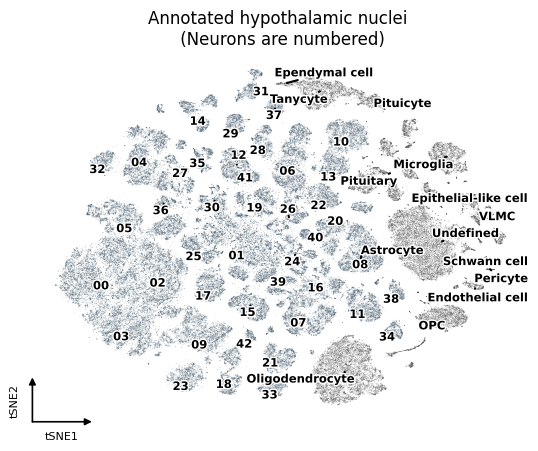

In [ ]:
import re
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText

# ── 1. Build short labels and assign grey colors per category ─────────────────
def transform_label(label):
    if re.match(r'^\d', label):
        return label.split('_')[0]
    elif 'Pituitary' in label:
        return 'Pituitary'
    else:
        return label.replace('_', ' ')

adata_mouse.obs['label_short'] = (
    adata_mouse.obs['detailed_celltype_annotation']
    .astype(str)
    .map(transform_label)
)

# Assign grey colors into adata.uns so sc.pl.embedding uses them directly
unique_labels = adata_mouse.obs['label_short'].unique()
color_dict = {}
for lbl in unique_labels:
    if re.match(r'^\d', adata_mouse.obs.loc[
            adata_mouse.obs['label_short'] == lbl,
            'detailed_celltype_annotation'].iloc[0]):
        color_dict[lbl] = '#536878'   # neurons: payne grey
    else:
        color_dict[lbl] = '#555555'   # glia: davey grey

cats = adata_mouse.obs['label_short'].astype('category').cat.categories
adata_mouse.obs['label_short'] = adata_mouse.obs['label_short'].astype('category')
adata_mouse.uns['label_short_colors'] = [color_dict[c] for c in cats]

fig = sc.pl.embedding(
    adata_mouse,
    basis="tsne",
    color="label_short",
    legend_loc="on data",
    legend_fontsize="small",
    alpha=0.5,
    return_fig=True,
    title="Annotated hypothalamic nuclei \n (Neurons are numbered)")
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Add white outline to all text labels for contrast
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
adjustText.adjust_text(
    ax.texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color='black', lw=1.5))
# Re-apply path effects after adjustText (it may reset them)
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
    
# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Figure_1b.pdf", bbox_inches='tight', dpi=600)
plt.show()

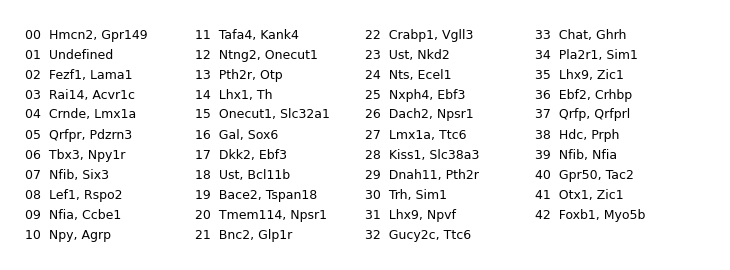

In [11]:
import re
import numpy as np
import matplotlib.pyplot as plt

# ── Build neuron number → marker gene string mapping ─────────────────────────
def marker_string(full_label):
    parts = full_label.split('_')
    return ', '.join(parts[1:])

neuron_obs = (
    adata_mouse.obs[['label_short', 'detailed_celltype_annotation']]
    .drop_duplicates('label_short')
    .copy()
)
neuron_obs = neuron_obs[
    neuron_obs['detailed_celltype_annotation'].str.match(r'^\d')
].copy()
neuron_obs['num'] = neuron_obs['label_short'].astype(str).astype(int)
neuron_obs = neuron_obs.sort_values('num')

entries = [(row['label_short'], marker_string(row['detailed_celltype_annotation']))
           for _, row in neuron_obs.iterrows()]

# ── Layout ────────────────────────────────────────────────────────────────────
N_COLS  = 4
N_ROWS  = int(np.ceil(len(entries) / N_COLS))
ROW_H   = 0.20
COL_W   = 1.7
PAD     = 0.15
FONTSIZE = 9

fig_w = COL_W * N_COLS + PAD * 2
fig_h = ROW_H * N_ROWS + PAD * 2

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_xlim(0, fig_w)
ax.set_ylim(0, fig_h)
ax.axis('off')

# Column-wise ordering: fill down each column before moving to the next
for i, (num, markers) in enumerate(entries):
    col = i // N_ROWS   # column-first indexing
    row = i % N_ROWS
    x0 = PAD + col * COL_W
    y0 = fig_h - PAD - (row + 0.5) * ROW_H
    ax.text(x0, y0, f"{num}  {markers}",
            ha='left', va='center', fontsize=FONTSIZE,
            color='black', transform=ax.transData)

plt.tight_layout(pad=0)
plt.savefig("Figure_1b_legend.pdf", bbox_inches='tight')
plt.show()

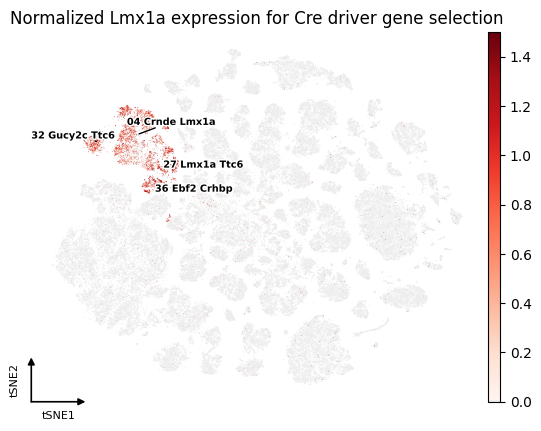

In [6]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText
from matplotlib.colors import LinearSegmentedColormap

base = plt.get_cmap("Reds")
colors = base(np.linspace(0, 1, 256))
colors[0] = mpl.colors.to_rgba("#ededed")  # force the very first color stop to light grey
cmap = LinearSegmentedColormap.from_list("bone_r_grey0", colors)

celltypes = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', "36_Ebf2_Crhbp"]
fig = sc.pl.embedding(
    adata_mouse,
    basis="tsne",
    color="Lmx1a",
    layer="scran_normalization",
    color_map=cmap,
    title="Normalized Lmx1a expression for Cre driver gene selection",
    return_fig=True,
    vmax=1.5)
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Compute centroid of each celltype in tSNE space and annotate
tsne_coords = adata_mouse.obsm["tsne"]
texts = []
for ct in celltypes:
    mask = adata_mouse.obs["detailed_celltype_annotation"] == ct
    if mask.sum() == 0:
        continue
    cx, cy = tsne_coords[mask].mean(axis=0)
    short = ct.replace("_", " ")
    t = ax.text(
        cx, cy, short,
        fontsize=7,
        fontweight="bold",
        ha="center", va="center",
        color="black",
        path_effects=[mpl.patheffects.withStroke(linewidth=2, foreground="white")]
    )
    texts.append(t)

# Move labels apart, drawing thin connector lines back to their original spot
adjustText.adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color='black', lw=1.0))

# Re-apply white-stroke outline (adjustText can reset path effects)
for t in texts:
    t.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])

# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Figure_4a.pdf", bbox_inches='tight', dpi=600)

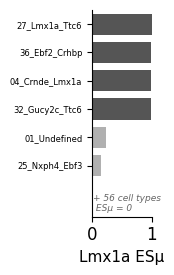

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

celltypes_highlight = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', "36_Ebf2_Crhbp"]

celltype_cellex = pd.read_csv("Cellex_7plex_detailed_annotation.csv", index_col=0)
lmx1a_esmu = celltype_cellex.loc["Lmx1a"].sort_values(ascending=True)

nonzero = lmx1a_esmu[lmx1a_esmu > 0]
zero    = lmx1a_esmu[lmx1a_esmu == 0]

bar_colors = ['#555555' if ct in celltypes_highlight else '#B0B0B0'
              for ct in nonzero.index]

fig_height = max(3, len(nonzero) * 0.22 + 0.6)  # compact, only nonzero rows get full height
fig, ax = plt.subplots(figsize=(2, fig_height))

ax.barh(range(len(nonzero)), nonzero.values, color=bar_colors, height=0.75)
ax.set_yticks(range(len(nonzero)))
ax.set_yticklabels(nonzero.index, fontsize=6)
ax.set_xlabel("Lmx1a ESµ", fontsize=11)
ax.set_xlim(0, 1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Summary row for all remaining zero-ESmu cell types
ax.text(
    0.02, -1.0, f"+ {len(zero)} cell types \n ESµ = 0",
    transform=ax.get_yaxis_transform(),  # x in data coords, y in axes-fraction-like (data) coords below row 0
    fontsize=6.5, style='italic', color='#666666', va='top'
)
ax.set_ylim(-1.8, len(nonzero) - 0.5)

plt.tight_layout()
plt.savefig("Figure_4b.pdf", bbox_inches='tight')
plt.show()

In [5]:
#del adata_mouse
adata_mouse = sc.read("atlas_merged_NTS_LPBN_retro_scran.h5ad")
# Exclude LPBN retrograde dataset before scoring
adata_mouse = adata_mouse[adata_mouse.obs["dataset"] != "LPBN retrograde (v36)"].copy()
adata_mouse

AnnData object with n_obs × n_vars = 205700 × 22180
    obs: 'nCount_RNA', 'nFeature_RNA', 'seurat_clusters', 'size_factors', 'sex', 'area', 'AAV', 'AAV_ratio', 'detailed_celltype_annotation', 'score_detailed_celltype_annotation', 'animal_id', 'lane_id', 'lane', 'sort', 'score_region_collapsed', 'neurotransmitter', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'cellect_bmi_detailed', 'cellect_bmi_detailed_BH', 'cellect_bmi_log10', 'detailed_significant_BH', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'region_collapsed', 'region_collapsed_filtered', 'cellect_bmi_manual', 'cellect_bmi_manual_BH', 'manual_significant_BH', 'leiden', 'dataset', 'source'
    obsm: 'X_tsne'
    layers: 'scran_normalization'

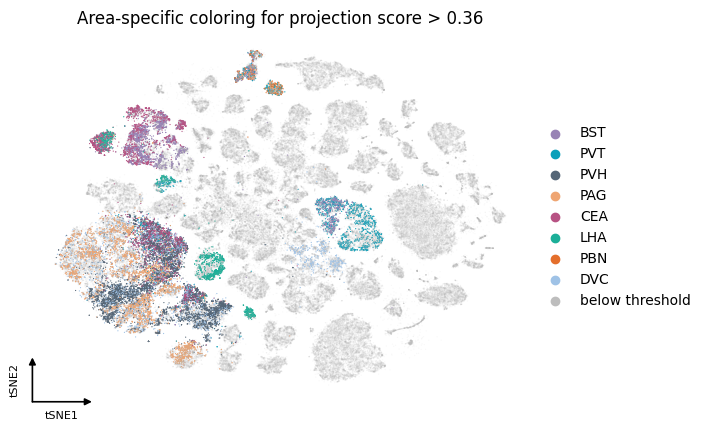

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

indir = "area_cellex_results"
# Loop through each CSV, pull out the v147 row, and build a per-area DataFrame
records = []
for fn in os.listdir(indir):
    if not fn.endswith("_detailed_cellex.csv"):
        continue
    area = fn.replace("_detailed_cellex.csv", "")
    df = pd.read_csv(os.path.join(indir, fn), index_col=0)
    if "v147" not in df.index:
        continue
    s = df.loc["v147"].rename(area)
    records.append(s)

# Combine into one DataFrame: rows=areas, cols=cell-types
combined = pd.DataFrame(records)
celltypes = sorted(adata_mouse.obs["detailed_celltype_annotation"].unique())
combined = combined.reindex(columns=celltypes, fill_value=0)
combined = combined.sort_index()

# Build one score per cell: value = table[area, celltype]
def lookup_score(row):
    area = row["area"]
    ct = row["detailed_celltype_annotation"]
    try:
        return combined.loc[area, ct]
    except KeyError:
        return np.nan

adata_mouse.obs["region_celltype_score"] = adata_mouse.obs.apply(lookup_score, axis=1)

score_col = "region_celltype_score"
area_col = "area"

# Region colors extracted from Projection targets panel
area_colors = {
    "BST": "#9883B5",
    "PVT": "#09A0BA",
    "PVH": "#556677",
    "PAG": "#EFA572",
    "CEA": "#B75283",
    "LHA": "#1BAF98",
    "PBN": "#E46F2C",
    "DVC": "#9FC2E6",
}
zero_color = "#BDBDBD"

# Build a new column: area name if score > 0.36, else "below threshold"
new_col = "area_score_color_label"
adata_mouse.obs[new_col] = np.where(
    adata_mouse.obs[score_col] > 0.36,
    adata_mouse.obs[area_col],
    "below threshold"
)
cats = list(area_colors.keys()) + ["below threshold"]
adata_mouse.obs[new_col] = adata_mouse.obs[new_col].astype(
    pd.CategoricalDtype(categories=cats, ordered=True)
)

# Install the matching color palette
palette = [area_colors[a] for a in area_colors.keys()] + [zero_color]
adata_mouse.uns[f"{new_col}_colors"] = palette

# Low alpha for "below threshold", full opacity for area-assigned cells
alpha_values = np.where(adata_mouse.obs[new_col] == "below threshold", 0.1, 1.0)

fig = sc.pl.embedding(
    adata_mouse,
    basis="tsne",
    color=new_col,
    size=3,
    alpha=alpha_values,
    title="Area-specific coloring for projection score > 0.36",
    return_fig=True)
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Figure_1c.pdf", bbox_inches='tight', dpi=600)

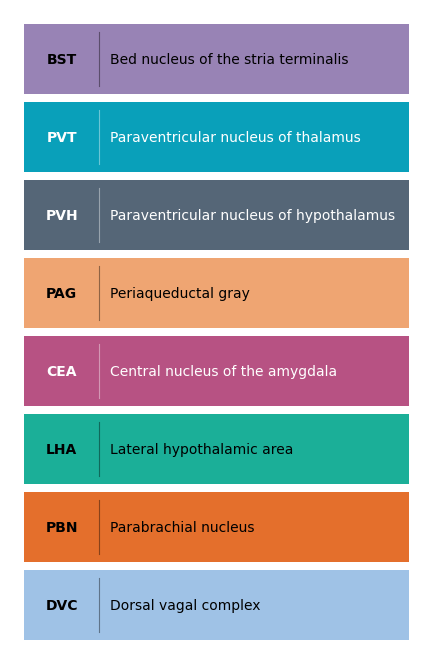

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

area_colors = {
    "BST": "#9883B5",
    "PVT": "#09A0BA",
    "PVH": "#556677",
    "PAG": "#EFA572",
    "CEA": "#B75283",
    "LHA": "#1BAF98",
    "PBN": "#E46F2C",
    "DVC": "#9FC2E6",
}

area_full_names = {
    "BST": "Bed nucleus of the stria terminalis",
    "PVT": "Paraventricular nucleus of thalamus",
    "PVH": "Paraventricular nucleus of hypothalamus",
    "PAG": "Periaqueductal gray",
    "CEA": "Central nucleus of the amygdala",
    "LHA": "Lateral hypothalamic area",
    "PBN": "Parabrachial nucleus",
    "DVC": "Dorsal vagal complex",
}

# ── Layout: vertical stack, one colored row per area ─────────────────────────
ROW_H   = 0.7
ROW_W   = 4.1
PAD     = 0.15
SPACING = 0.08
ABBREV_W = 0.8   # width of the abbreviation block on the left

fig_w = ROW_W + PAD * 2
fig_h = len(area_colors) * (ROW_H + SPACING) - SPACING + PAD * 2

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
ax.set_xlim(0, fig_w)
ax.set_ylim(0, fig_h)
ax.axis('off')

for i, (area, color) in enumerate(area_colors.items()):
    x0 = PAD
    y0 = fig_h - PAD - (i + 1) * ROW_H - i * SPACING

    # Full-width colored background rectangle
    rect = mpatches.FancyBboxPatch(
        (x0, y0), ROW_W, ROW_H,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=color, transform=ax.transData, clip_on=False)
    ax.add_patch(rect)

    r, g, b = mpatches.colors.to_rgb(color)
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    text_color = 'white' if luminance < 0.5 else 'black'

    # Abbreviation on the left, bold
    ax.text(x0 + ABBREV_W / 2, y0 + ROW_H / 2, area,
            ha='center', va='center', fontsize=10,
            fontweight='bold', color=text_color,
            transform=ax.transData)

    # Thin divider line between abbreviation and full name
    ax.plot([x0 + ABBREV_W, x0 + ABBREV_W], [y0 + 0.08, y0 + ROW_H - 0.08],
            color=text_color, lw=0.8, alpha=0.4, transform=ax.transData)

    # Full anatomical name to the right
    ax.text(x0 + ABBREV_W + 0.12, y0 + ROW_H / 2,
            area_full_names[area],
            ha='left', va='center', fontsize=10,
            color=text_color, transform=ax.transData,
            linespacing=1.3)

plt.tight_layout(pad=0)
plt.savefig("Figure_1c_legend.pdf", bbox_inches='tight')
plt.show()

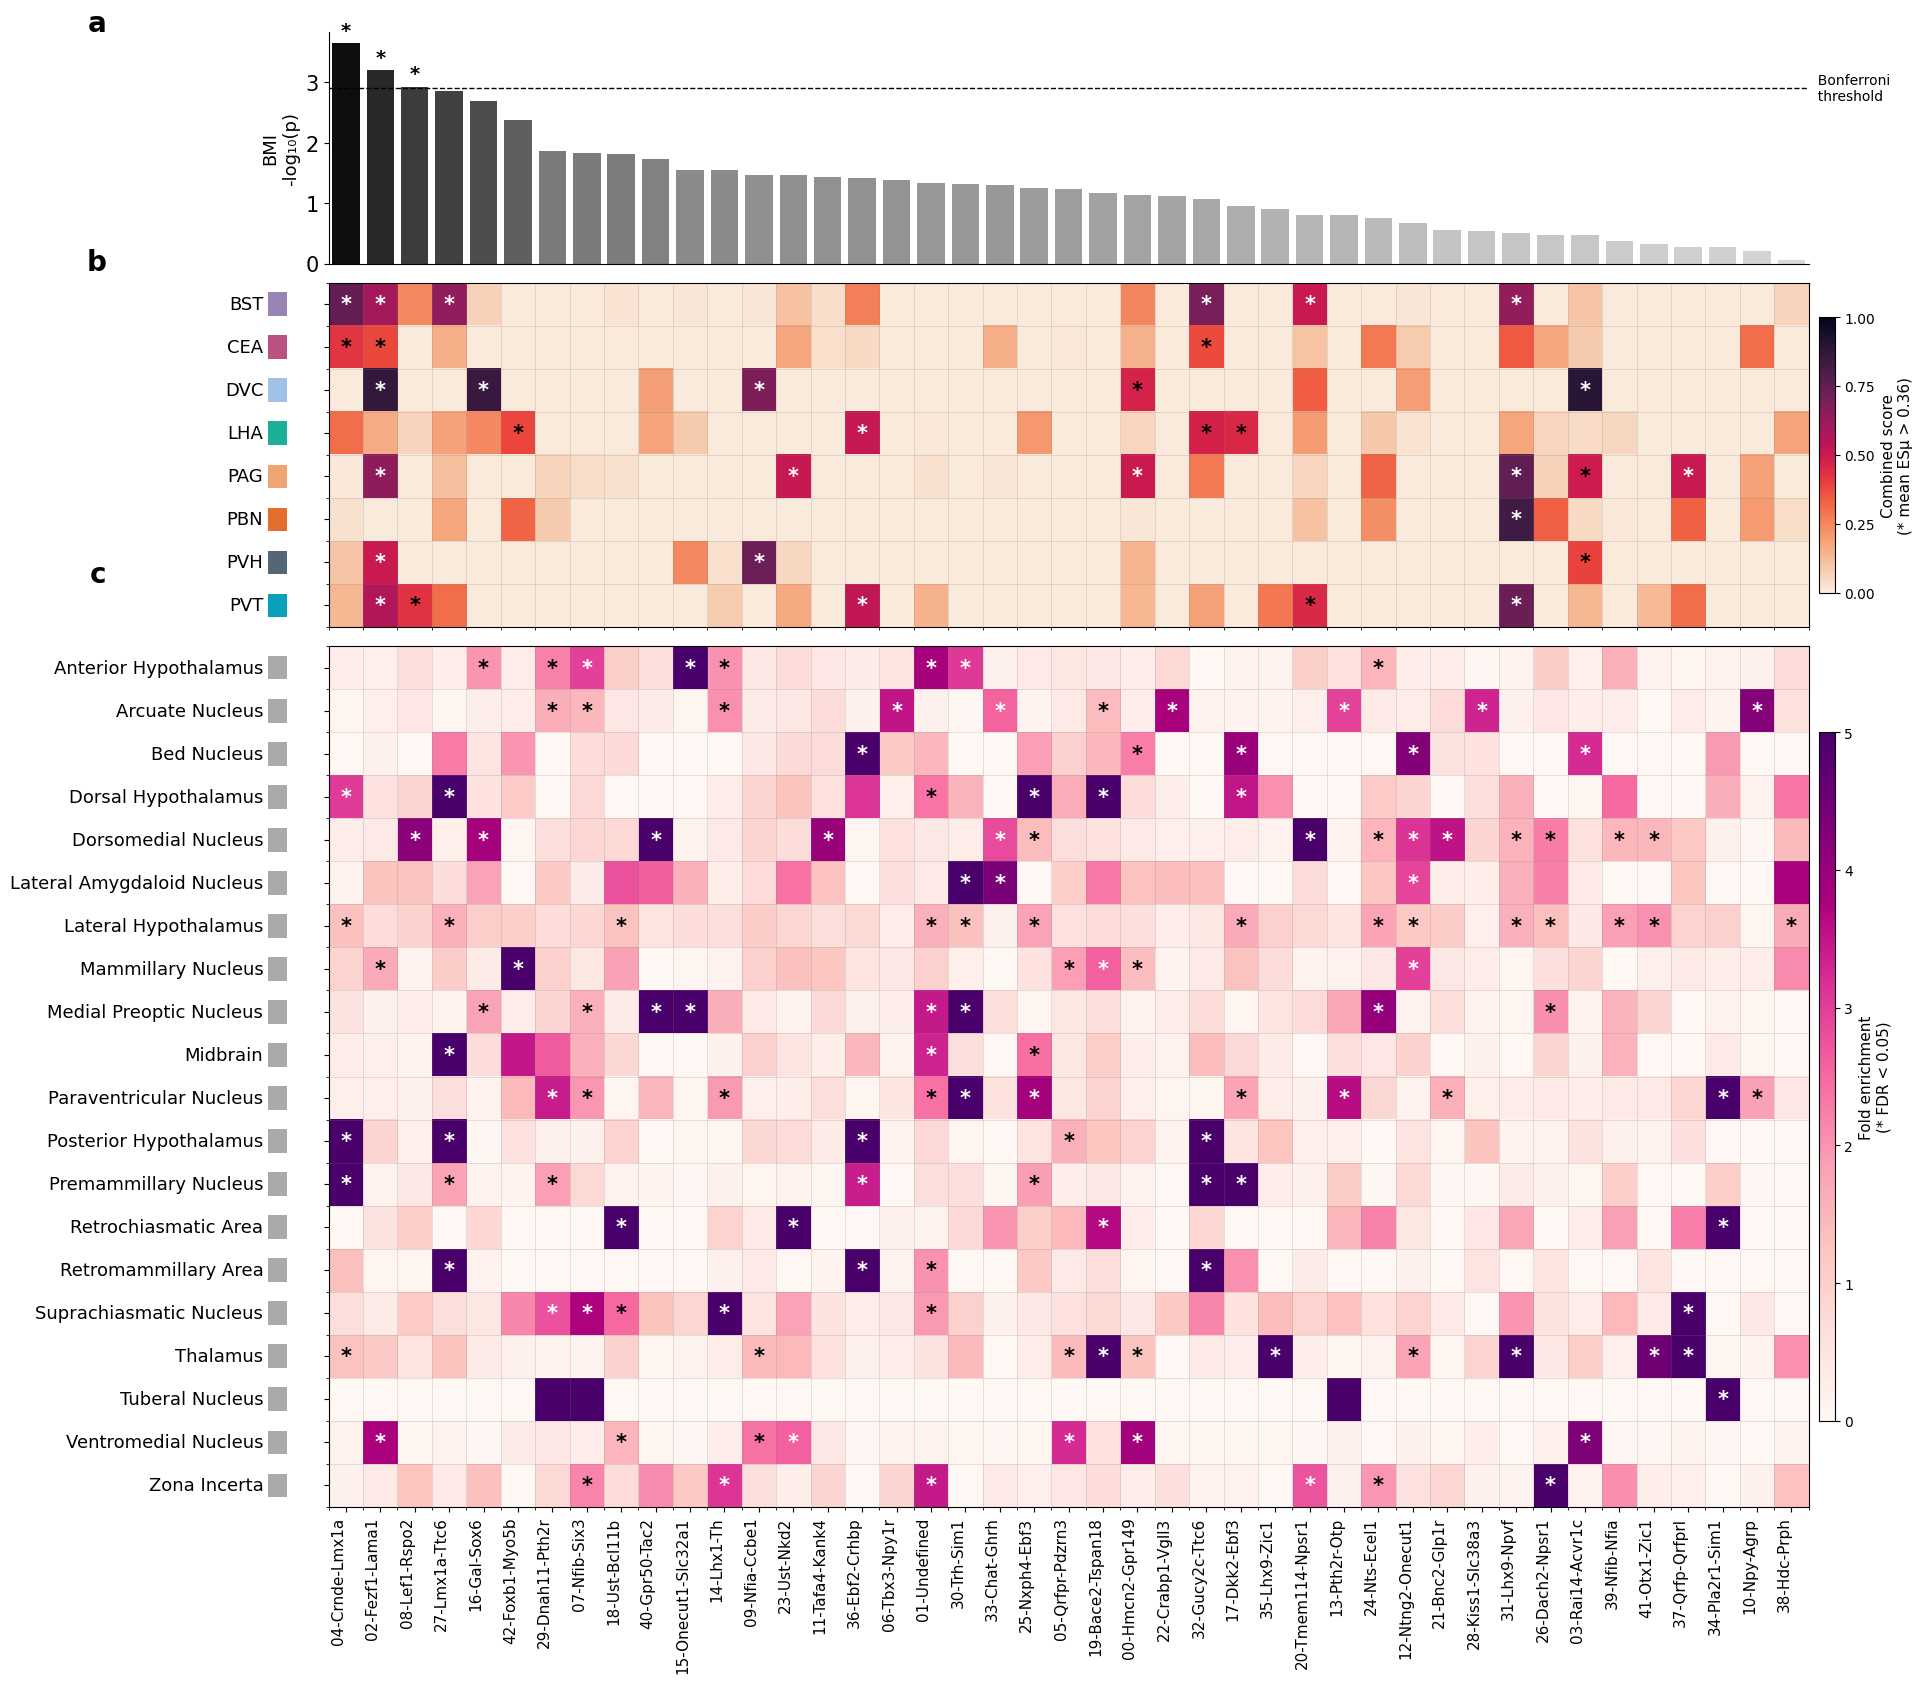

In [13]:
import os
import re
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ── 0. Global font sizes ──────────────────────────────────────────────────────
mpl.rcParams.update({
    'font.size':             15,
    'ytick.labelsize':       15,
    'xtick.labelsize':       12,
    'legend.fontsize':       15,
    'legend.title_fontsize': 15,
})

# ── 1. Shared setup ───────────────────────────────────────────────────────────
# Keep only neuronal clusters (labels starting with a digit, e.g. "06_Tbx3_Npy1r")
cell_type_order_orig = sorted(
    ct for ct in adata_mouse.obs['detailed_celltype_annotation'].unique()
    if re.match(r'^\d', ct)
)
all_celltypes = sorted(adata_mouse.obs['detailed_celltype_annotation'].unique())

# --- Rebuild combined (snRNA, all 8 areas) fresh from area_cellex_results ────
indir = "area_cellex_results"
records = []
for fn in os.listdir(indir):
    if not fn.endswith("_detailed_cellex.csv"):
        continue
    area = fn.replace("_detailed_cellex.csv", "")
    if area in ("spatial1", "spatial2", "spatial3"):
        continue  # these are spatial runs, handled separately below
    df = pd.read_csv(os.path.join(indir, fn), index_col=0)
    if "v147" not in df.index:
        continue
    s = df.loc["v147"].rename(area)
    records.append(s)

combined = pd.DataFrame(records)
combined = combined.reindex(columns=all_celltypes, fill_value=0)
combined = combined.sort_index()

# --- Rebuild combined_spatial (6 areas only: PAG, BST, PBN, LHA, CEA, PVT) ───
runs  = ["spatial1", "spatial2", "spatial3"]
genes = ["p36-NLS-Cre", "p147-mCherry-2A-iCre"]
gene_area_map = {
    "spatial1": {"p36-NLS-Cre": "PAG", "p147-mCherry-2A-iCre": "BST"},
    "spatial2": {"p36-NLS-Cre": "PBN", "p147-mCherry-2A-iCre": "LHA"},
    "spatial3": {"p36-NLS-Cre": "CEA", "p147-mCherry-2A-iCre": "PVT"},
}

records = []
for run in runs:
    fn = f"{run}_detailed_cellex.csv"
    path = os.path.join(indir, fn)
    df = pd.read_csv(path, index_col=0)
    for gene in genes:
        if gene not in df.index:
            raise KeyError(f"Gene {gene!r} not found in {fn}")
        area = gene_area_map[run][gene]
        s = df.loc[gene].rename(area)
        records.append(s)

combined_spatial = pd.DataFrame(records)
combined_spatial = combined_spatial.reindex(columns=all_celltypes, fill_value=0)

combined_spatial_csv = pd.read_csv("df_spatial.csv")  # not needed anymore, kept import-free
combined_spatial_csv = pd.read_csv("df_spatial.csv")

# --- GWAS BMI ───────────────────────────────────────────────────────────────
df_cellect  = pd.read_csv('df_cellect.csv')
df_cellect  = df_cellect[df_cellect['gwas'] == 'BMI_Loh2018_UKBB_munged_txt'].copy()
df_cellect['gwas'] = 'BMI'
pivot_gwas  = df_cellect.pivot(index='gwas', columns='annotation', values='mlog10p')
pivot_gpval = df_cellect.pivot(index='gwas', columns='annotation', values='pvalue')
bonferroni  = 0.05 / 41

gwas_series  = pivot_gwas.loc['BMI']
gpval_series = pivot_gpval.loc['BMI']

# Ordering: descending -log10(p), cell types without GWAS data pushed to the end
has_gwas    = [ct for ct in cell_type_order_orig if ct in gwas_series.index and not np.isnan(gwas_series[ct])]
no_gwas     = [ct for ct in cell_type_order_orig if ct not in has_gwas]
has_gwas_sorted = sorted(has_gwas, key=lambda ct: gwas_series[ct], reverse=True)
cell_type_order = has_gwas_sorted + no_gwas
n_cols = len(cell_type_order)
col_idx_map = {ct: i for i, ct in enumerate(cell_type_order)}

sig_cell_types = [ct for ct in has_gwas_sorted if gpval_series[ct] < bonferroni]

# --- Combined projection score (8 regions; PVH/DVC = snRNA only, no averaging) ─
single_dataset_regions = {'PVH', 'DVC'}
score_df = pd.DataFrame(index=combined.index, columns=cell_type_order, dtype=float)
for region in combined.index:
    for celltype in cell_type_order:
        snrna_val   = combined.loc[region, celltype] \
                      if celltype in combined.columns else np.nan
        spatial_val = combined_spatial.loc[region, celltype] \
                      if (region in combined_spatial.index
                          and celltype in combined_spatial.columns) else np.nan
        if np.isnan(snrna_val) and np.isnan(spatial_val):
            score_df.loc[region, celltype] = np.nan
        elif region in single_dataset_regions:
            score_df.loc[region, celltype] = np.nansum([snrna_val, spatial_val])
        else:
            score_df.loc[region, celltype] = np.nansum([snrna_val, spatial_val]) / 2

score_array  = score_df.values.astype(float)
score_norm   = Normalize(vmin=0, vmax=1)
score_cmap   = sns.color_palette("rocket_r", as_cmap=True)
score_cmap.set_bad(color='lightgray')
n_rows_score = len(score_df.index)

# --- Enrichment ─────────────────────────────────────────────────────────────
df_enrichment = pd.read_csv("celltype_region_enrichment_all.csv")
pivot_fold    = df_enrichment.pivot(index='region', columns='celltype', values='fold_enrichment')
pivot_epval   = df_enrichment.pivot(index='region', columns='celltype', values='pvalue_adj')
common_enrich = [ct for ct in cell_type_order if ct in pivot_fold.columns]
pivot_fold    = pivot_fold[common_enrich]
pivot_epval   = pivot_epval[common_enrich]
sig_mask      = pivot_epval < 0.05
n_rows_enrich = len(pivot_fold.index)

# ── 2. Figure layout ──────────────────────────────────────────────────────────
fig_width = 20
cell_size = fig_width / n_cols

gwas_h = 2.5
height_ratios = [
    gwas_h,
    n_rows_score  * cell_size,
    n_rows_enrich * cell_size,
]
fig_height = sum(height_ratios)

fig = plt.figure(figsize=(fig_width, fig_height))
gs  = gridspec.GridSpec(
    3, 1,
    height_ratios=height_ratios,
    hspace=0.04,
    left=0.08, right=0.82,
    top=0.99, bottom=0.04
)

ax_gwas   = fig.add_subplot(gs[0])
ax_score  = fig.add_subplot(gs[1])
ax_enrich = fig.add_subplot(gs[2])

xlim = (-0.5, n_cols - 0.5)

# ── 3. GWAS BMI bar plot (top panel) ──────────────────────────────────────────
bar_heights = [gwas_series[ct] if ct in gwas_series.index and not np.isnan(gwas_series[ct]) else 0
               for ct in cell_type_order]

valid_heights = [h for h in bar_heights if h > 0]
h_min, h_max  = min(valid_heights), max(valid_heights)
grey_cmap     = plt.get_cmap('Greys')

bar_colors = []
for ct, h in zip(cell_type_order, bar_heights):
    if h == 0:
        bar_colors.append('lightgray')
    else:
        intensity = 0.25 + 0.70 * (h - h_min) / (h_max - h_min)
        bar_colors.append(grey_cmap(intensity))

ax_gwas.bar(range(n_cols), bar_heights, color=bar_colors, width=0.8, edgecolor='none')

bonf_line = -np.log10(bonferroni)
ax_gwas.axhline(bonf_line, color='black', linestyle='--', linewidth=1)
ax_gwas.text(n_cols - 0.5, bonf_line, '  Bonferroni\n  threshold',
             ha='left', va='center', fontsize=10, color='black', clip_on=False)

for i, ct in enumerate(cell_type_order):
    if ct in sig_cell_types:
        ax_gwas.text(i, bar_heights[i] + 0.05, '*',
                     ha='center', va='bottom', fontsize=14,
                     fontweight='bold', color='black')

ax_gwas.set_xlim(xlim)
ax_gwas.set_ylabel('BMI\n-log₁₀(p)', fontsize=13)
ax_gwas.set_xticks([])
ax_gwas.spines['top'].set_visible(False)
ax_gwas.spines['right'].set_visible(False)

# ── 4. Combined projection score ──────────────────────────────────────────────
# Region colors extracted from Projection targets panel
area_colors = {
    "BST": "#9883B5",
    "PVT": "#09A0BA",
    "PVH": "#556677",
    "PAG": "#EFA572",
    "CEA": "#B75283",
    "LHA": "#1BAF98",
    "PBN": "#E46F2C",
    "DVC": "#9FC2E6",
}

im_score = ax_score.imshow(np.ma.masked_invalid(score_array),
                            aspect='auto', cmap=score_cmap, norm=score_norm,
                            interpolation='nearest')
ax_score.set_xlim(xlim)
ax_score.set_yticks(range(n_rows_score))
ax_score.set_yticklabels([])  # replaced by manual labels + color squares below
ax_score.set_xticks([])
ax_score.set_xticks(np.arange(-.5, n_cols, 1), minor=True)
ax_score.set_yticks(np.arange(-.5, n_rows_score, 1), minor=True)
ax_score.grid(which='minor', color='gray', linestyle='-', linewidth=0.5, alpha=0.3)

for row_i, region in enumerate(score_df.index):
    for col_i in range(n_cols):
        val = score_array[row_i, col_i]
        if np.isnan(val):
            continue
        if val > 0.36:
            brightness = score_norm(val)
            text_color = 'white' if brightness > 0.5 else 'black'
            ax_score.text(col_i, row_i, '*', ha='center', va='center',
                          fontsize=15, color=text_color, fontweight='bold')

# Colored square + area label to the left of each score row
sq_size = 0.55   # square height/width in data units
sq_gap  = 1.2    # distance from left edge of heatmap to right edge of square (data units)
for row_i, region in enumerate(score_df.index):
    color = area_colors.get(region, '#AAAAAA')
    sq_x = -0.5 - sq_gap - sq_size
    sq_y = row_i - sq_size / 2
    ax_score.add_patch(mpl.patches.FancyBboxPatch(
        (sq_x, sq_y), sq_size, sq_size,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=color, clip_on=False,
        transform=ax_score.transData))
    ax_score.text(sq_x - 0.15, row_i, region,
                  ha='right', va='center', fontsize=13,
                  transform=ax_score.transData)

# ── 5. Enrichment heatmap ─────────────────────────────────────────────────────
enrich_full = np.full((n_rows_enrich, n_cols), np.nan)
for j, ct in enumerate(common_enrich):
    if ct in col_idx_map:
        enrich_full[:, col_idx_map[ct]] = pivot_fold.values[:, j]

enrich_cmap = plt.get_cmap('RdPu')
enrich_cmap.set_bad(color='lightgray')
im_enrich = ax_enrich.imshow(np.ma.masked_invalid(enrich_full),
                              aspect='auto', cmap=enrich_cmap,
                              vmin=0, vmax=5, interpolation='nearest')
ax_enrich.set_xlim(xlim)
ax_enrich.set_yticks(range(n_rows_enrich))
ax_enrich.set_yticklabels([])  # replaced by manual labels + color squares below
ax_enrich.set_xticks(range(n_cols))

# x-axis: capitalize region names, replace underscores with spaces,
# cell type IDs replace underscores with dashes
def format_ct_label(ct):
    return ct.replace('_', '-')

ax_enrich.set_xticklabels([format_ct_label(ct) for ct in cell_type_order],
                            rotation=90, ha='right', fontsize=11)
ax_enrich.set_xticks(np.arange(-.5, n_cols, 1), minor=True)
ax_enrich.set_yticks(np.arange(-.5, n_rows_enrich, 1), minor=True)
ax_enrich.grid(which='minor', color='gray', linestyle='-', linewidth=0.5, alpha=0.3)

for i in range(n_rows_enrich):
    for j, ct in enumerate(common_enrich):
        if sig_mask.iloc[i, j] and ct in col_idx_map:
            col_pos    = col_idx_map[ct]
            brightness = enrich_full[i, col_pos] / 5
            ax_enrich.text(col_pos, i, '*', ha='center', va='center',
                           color='white' if brightness > 0.5 else 'black',
                           fontsize=15, fontweight='bold')

# Colored square + area label to the left of each enrichment row
for row_i, region in enumerate(pivot_fold.index):
    color = area_colors.get(region, '#AAAAAA')
    sq_x = -0.5 - sq_gap - sq_size
    sq_y = row_i - sq_size / 2
    ax_enrich.add_patch(mpl.patches.FancyBboxPatch(
        (sq_x, sq_y), sq_size, sq_size,
        boxstyle="square,pad=0", linewidth=0,
        facecolor=color, clip_on=False, zorder=5,
        transform=ax_enrich.transData))
    ax_enrich.text(sq_x - 0.15, row_i,
                   region.replace('_', ' ').title(),
                   ha='right', va='center', fontsize=13,
                   transform=ax_enrich.transData,
                   bbox=dict(boxstyle='square,pad=0',
                             facecolor='none', edgecolor='none'))

# ── 6. Colorbars via fig.add_axes (fixes PDF export rendering bug) ────────────
fig.canvas.draw()

cbar_padding = 0.005
cbar_width   = 0.008

pos = ax_score.get_position()
cax_score  = fig.add_axes([pos.x1 + cbar_padding, pos.y0 + pos.height * 0.1,
                            cbar_width, pos.height * 0.8])
cbar_score = fig.colorbar(ScalarMappable(norm=score_norm, cmap=score_cmap), cax=cax_score)
cbar_score.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar_score.set_label('Combined score\n(* mean ESµ > 0.36)', fontsize=11)
cbar_score.ax.tick_params(labelsize=10)

pos = ax_enrich.get_position()
cax_enrich  = fig.add_axes([pos.x1 + cbar_padding, pos.y0 + pos.height * 0.1,
                             cbar_width, pos.height * 0.8])
cbar_enrich = fig.colorbar(im_enrich, cax=cax_enrich)
cbar_enrich.set_ticks([0, 1, 2, 3, 4, 5])
cbar_enrich.set_label('Fold enrichment\n(* FDR < 0.05)', fontsize=11)
cbar_enrich.ax.tick_params(labelsize=10)

# ── Panel labels (a, b, c) ─────────────────────────────────────────────────
for ax, label in zip([ax_gwas, ax_score, ax_enrich], ['a', 'b', 'c']):
    ax.text(-0.15, 1.1, label, transform=ax.transAxes,
            fontsize=20, fontweight='bold', ha='right', va='top')
# ── 7. Save ───────────────────────────────────────────────────────────────────
plt.savefig('Figure_3.pdf', bbox_inches='tight', dpi=600)
plt.show()

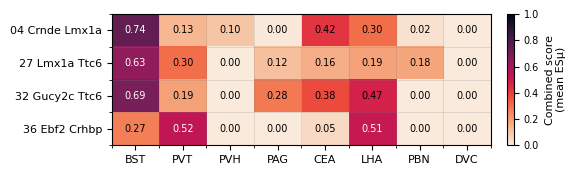

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

celltypes_highlight = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', "36_Ebf2_Crhbp"]

area_colors = {
    "BST": "#9883B5", "PVT": "#09A0BA", "PVH": "#556677",
    "PAG": "#EFA572", "CEA": "#B75283", "LHA": "#1BAF98",
    "PBN": "#E46F2C", "DVC": "#9FC2E6",
}
area_order = list(area_colors.keys())

score_subset = score_df[celltypes_highlight].T
score_subset = score_subset.reindex(columns=area_order)   # reorder areas

fig, ax = plt.subplots(figsize=(6, 2))
norm = Normalize(vmin=0, vmax=1)

im = ax.imshow(np.ma.masked_invalid(score_subset.values),
                aspect='auto', cmap=score_cmap, norm=norm, interpolation='nearest')

ax.set_xticks(range(score_subset.shape[1]))
ax.set_xticklabels(score_subset.columns, fontsize=8)
ax.set_yticks(range(score_subset.shape[0]))
ax.set_yticklabels([ct.replace('_', ' ') for ct in score_subset.index], fontsize=8)
ax.set_xticks(np.arange(-.5, score_subset.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, score_subset.shape[0], 1), minor=True)
ax.grid(which='minor', color='gray', linestyle='-', linewidth=0.5, alpha=0.3)

for i in range(score_subset.shape[0]):
    for j in range(score_subset.shape[1]):
        val = score_subset.values[i, j]
        if np.isnan(val):
            continue
        brightness = norm(val)
        text_color = 'white' if brightness > 0.5 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                fontsize=7, color=text_color)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Combined score\n(mean ESµ)', fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig("Figure_4d.pdf", bbox_inches='tight')
plt.show()

In [ ]:
adata = sc.read("hypomap_slim_norm.h5ad")
adata

AnnData object with n_obs × n_vars = 433369 × 60333
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Cell_ID', 'Sample_ID', 'Donor_ID', 'Dataset', 'sex', 'age_years', 'percent.mt', 'Technology', 'celltype_annotation', 'C0', 'C1', 'C2', 'C3', 'C4', 'C0_named', 'C1_named', 'C2_named', 'C3_named', 'C4_named', 'region'
    var: 'features'
    uns: 'celltype_annotation_colors', 'log1p'
    obsm: 'X_scvi', 'X_umap'
    layers: 'counts', 'norm'

In [4]:
adata_mouse_sub = sc.read("LMX_bipca.h5ad")
adata_mouse_sub

/cluster/home/bcoester/miniconda3/envs/bipca_env/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 11397 × 15916
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'old.ident', 'hash.mcl.ID', 'seurat_clusters', 'sex', 'area', 'lane', 'sort', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'detailed_celltype_annotation', 'leiden', 'size_factors', 'cellect_bmi_manual', 'cellect_bmi_detailed', 'cellect_bmi_manual_BH', 'cellect_bmi_detailed_BH', 'manual_significant_BH', 'detailed_significant_BH', 'AAV', 'AAV_ratio', 'cellect_bmi_log10', 'region_collapsed', 'score_region_collapsed', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'region_collapsed_filtered', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'plot', 'neurotransmitter', 'viral_zscore_animal', 'viral_zscore_animal_capped', 'virus_positive', 'celltype_HM', 'score_celltype_HM', 'region_HM', 'score_region_HM', 'C1_HM', 'score_C1_HM', 'C2_HM', 'score_C2_HM', 'C3_HM', 'score_C3_HM', 'C4_HM', 'score_C4_HM', 'region_HM_f

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# GMM filtering of C4_HM label transfer scores — all Lmx1a cells
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.mixture import GaussianMixture
from scipy.stats import norm

MOUSE_CELLTYPES = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6',
                   '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp']
MOUSE_COLORS = {
    '04_Crnde_Lmx1a': '#008941',
    '27_Lmx1a_Ttc6':  '#ffaa92',
    '32_Gucy2c_Ttc6': '#000035',
    '36_Ebf2_Crhbp':  '#0aa6d8',
}
SCORE_COL = 'score_C4_HM'

plt.rcParams.update({'font.size': 9, 'figure.dpi': 150,
                     'savefig.dpi': 300, 'pdf.fonttype': 42})

# ── 1. Extract scores for all Lmx1a cells ────────────────────────────────────
obs = adata_mouse_sub.obs.copy()
obs['C4_short'] = obs['C4_HM'].str.extract(r'(C4-\d+)')
obs[SCORE_COL]  = pd.to_numeric(obs[SCORE_COL], errors='coerce')

lmx_mask = obs['detailed_celltype_annotation'].isin(MOUSE_CELLTYPES)
obs_lmx  = obs[lmx_mask].dropna(subset=[SCORE_COL]).copy()
scores   = obs_lmx[SCORE_COL].values.reshape(-1, 1)

print(f"Lmx1a cells with valid score: {len(obs_lmx)}")

# ── 2. Fit 2-component GMM ────────────────────────────────────────────────────
gmm = GaussianMixture(n_components=2, random_state=42, max_iter=500)
gmm.fit(scores)

# Label components: signal = higher mean
comp_means  = gmm.means_.flatten()
signal_comp = int(np.argmax(comp_means))
noise_comp  = 1 - signal_comp

# Posterior P(signal | score) per cell
posteriors  = gmm.predict_proba(scores)[:, signal_comp]
obs_lmx['gmm_p_signal']  = posteriors
obs_lmx['gmm_label']     = np.where(posteriors >= 0.5, 'signal', 'noise')

# Decision boundary: score where P(signal) = P(noise) = 0.5
x_grid     = np.linspace(scores.min(), scores.max(), 2000).reshape(-1, 1)
post_grid  = gmm.predict_proba(x_grid)[:, signal_comp]
cross_idx  = np.argmin(np.abs(post_grid - 0.5))
gmm_threshold = float(x_grid[cross_idx])

n_signal = (obs_lmx['gmm_label'] == 'signal').sum()
n_noise  = (obs_lmx['gmm_label'] == 'noise').sum()
print(f"\nGMM threshold (P=0.5 crossing): {gmm_threshold:.4f}")
print(f"Signal: {n_signal} cells ({n_signal/len(obs_lmx)*100:.1f}%)")
print(f"Noise : {n_noise}  cells ({n_noise/len(obs_lmx)*100:.1f}%)")
print(f"\nGMM components:")
for i, (comp, label) in enumerate([(signal_comp, 'signal'), (noise_comp, 'noise')]):
    print(f"  {label}: μ={comp_means[comp]:.4f}  "
          f"σ={np.sqrt(gmm.covariances_.flatten()[comp]):.4f}  "
          f"weight={gmm.weights_[comp]:.3f}")

# ── Per-celltype breakdown ─────────────────────────────────────────────────
print("\nRetention by mouse celltype:")
ct_summary = (obs_lmx.groupby('detailed_celltype_annotation')
              .apply(lambda x: pd.Series({
                  'n_total':  len(x),
                  'n_signal': (x['gmm_label'] == 'signal').sum(),
                  'pct_kept': (x['gmm_label'] == 'signal').mean() * 100,
                  'mean_score': x[SCORE_COL].mean(),
                  'mean_p_signal': x['gmm_p_signal'].mean(),
              }))
              .reset_index())
print(ct_summary.to_string(index=False))

# ── Store filtered cell index for use in Sankey ───────────────────────────
gmm_signal_idx = obs_lmx[obs_lmx['gmm_label'] == 'signal'].index
print(f"\ngmm_signal_idx: {len(gmm_signal_idx)} cells ready for filtered Sankey")

Lmx1a cells with valid score: 11397

GMM threshold (P=0.5 crossing): 0.4207
Signal: 3410 cells (29.9%)
Noise : 7987  cells (70.1%)

GMM components:
  signal: μ=0.5364  σ=0.1613  weight=0.336
  noise: μ=0.2648  σ=0.0890  weight=0.664

Retention by mouse celltype:
detailed_celltype_annotation  n_total  n_signal  pct_kept  mean_score  mean_p_signal
              04_Crnde_Lmx1a   6377.0    2176.0 34.122628    0.372457       0.380427
               27_Lmx1a_Ttc6   2296.0     365.0 15.897213    0.296656       0.215711
              32_Gucy2c_Ttc6   1596.0     639.0 40.037594    0.407794       0.430284
               36_Ebf2_Crhbp   1128.0     230.0 20.390071    0.312205       0.256394

gmm_signal_idx: 3410 cells ready for filtered Sankey


/scratch/tmp.5335658.bcoester/ipykernel_3155931/1181993841.py:54: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gmm_threshold = float(x_grid[cross_idx])
/scratch/tmp.5335658.bcoester/ipykernel_3155931/1181993841.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_summary = (obs_lmx.groupby('detailed_celltype_annotation')
/scratch/tmp.5335658.bcoester/ipykernel_3155931/1181993841.py:70: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to ex

/scratch/tmp.5335658.bcoester/ipykernel_3155931/1559007571.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'C4_short'])


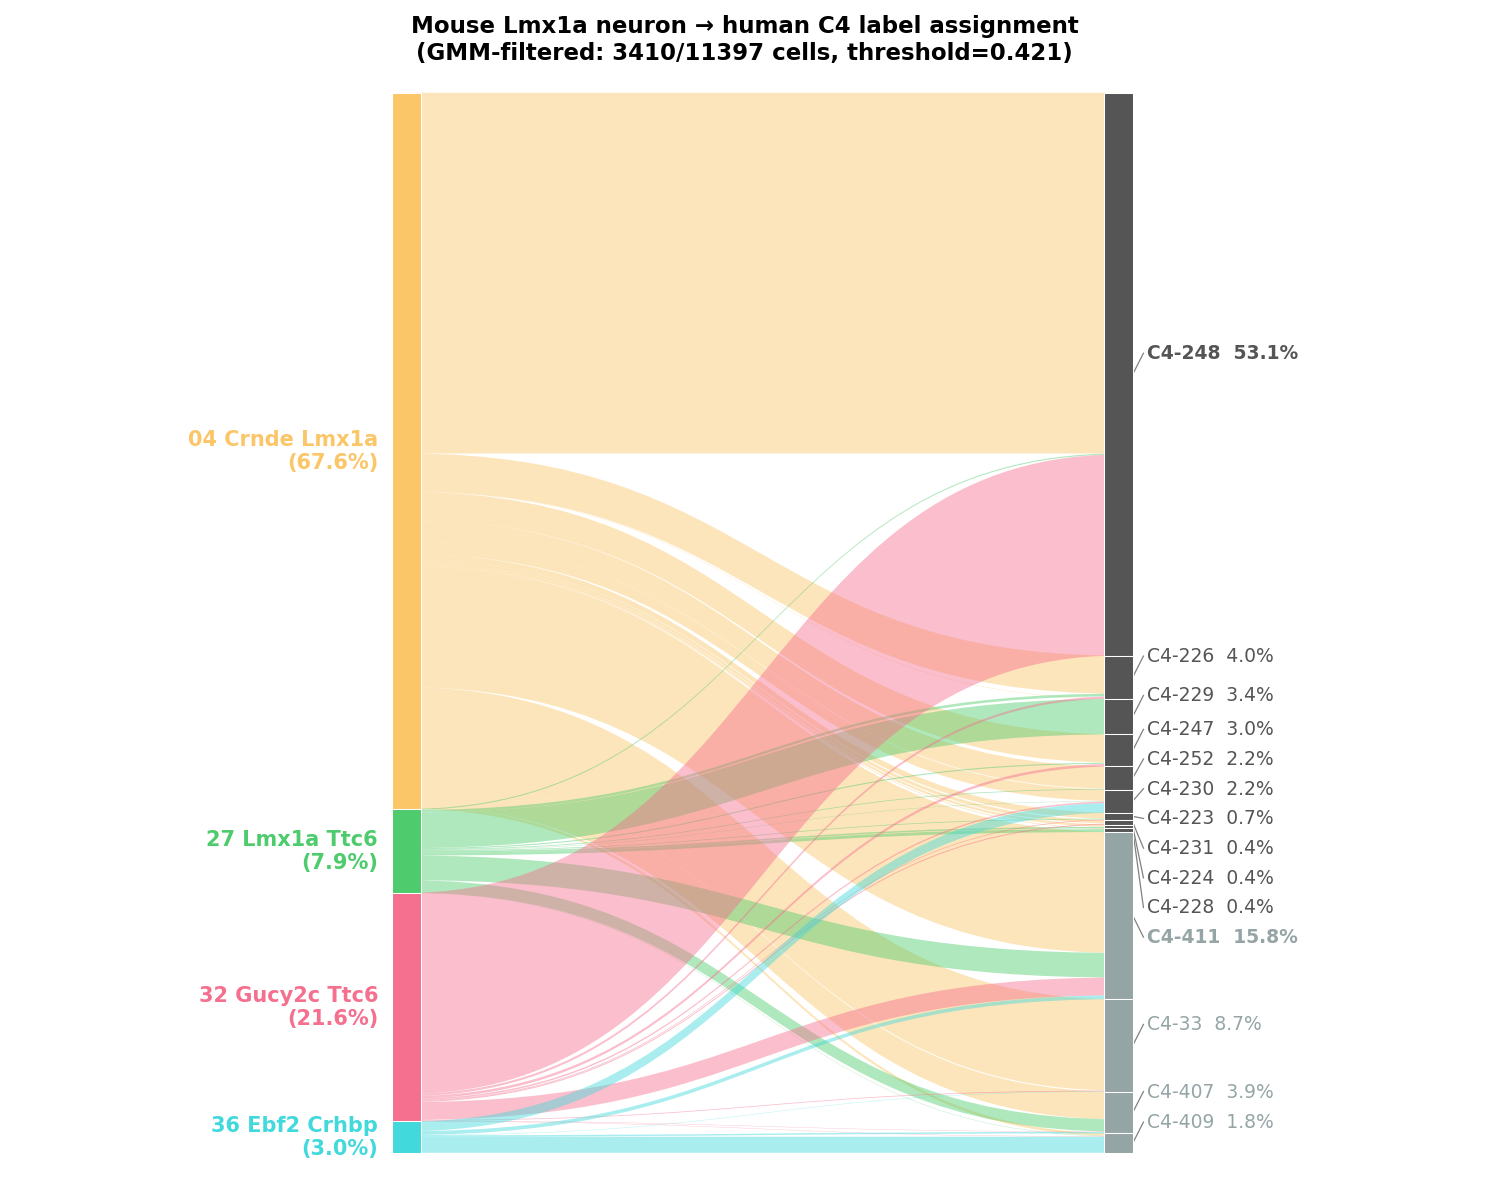

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path
from matplotlib.patches import PathPatch

C4_GROUP_COLORS = {
    'Group A':  '#555555',
    'Group B':  '#95a5a6',
}
BOLD_C4 = {'C4-248', 'C4-411'}

# ── 1. Compute cross-tabulation from GMM-filtered mouse obs ──────────────────
MOUSE_CELLTYPES = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6',
                    '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp']

MOUSE_COLORS = {
    '04_Crnde_Lmx1a': '#fbc668',
    '27_Lmx1a_Ttc6':  '#4ecc6d',
    '32_Gucy2c_Ttc6': '#f56f8e',
    '36_Ebf2_Crhbp':  '#42d9dc',
}

lmx_obs = adata_mouse_sub.obs.loc[gmm_signal_idx].copy()
lmx_obs['C4_short'] = lmx_obs['C4_HM'].str.extract(r'(C4-\d+)')
lmx_obs['C4_short'] = lmx_obs['C4_short'].astype(str)

ALL_C4 = LMX_C4_ALL  # GROUP_A_C4 + GROUP_B_C4

xtab = (lmx_obs[lmx_obs['C4_short'].isin(ALL_C4)]
        .groupby(['detailed_celltype_annotation', 'C4_short'])
        .size()
        .unstack(fill_value=0))

for c in ALL_C4:
    if c not in xtab.columns:
        xtab[c] = 0

c4_totals = xtab.sum(axis=0)
c4_order = (sorted(GROUP_A_C4, key=lambda c: -c4_totals.get(c, 0)) +
            sorted(GROUP_B_C4, key=lambda c: -c4_totals.get(c, 0)))
c4_order = [c for c in c4_order if c in xtab.columns]
xtab = xtab[c4_order]

# ── 2. Layout constants ───────────────────────────────────────────────────────
fig, ax_s = plt.subplots(figsize=(10, 8))

X_L, X_R = 0.0, 1.0

# ── 3. Node y-positions ───────────────────────────────────────────────────────
ct_totals = xtab.sum(axis=1)
grand_total = ct_totals.sum()

ct_heights = ct_totals / grand_total
ct_y_bottom = {}
y = 1.0
for ct in MOUSE_CELLTYPES:
    h = ct_heights.get(ct, 0)
    ct_y_bottom[ct] = y - h
    y -= h
ct_y_top = {ct: ct_y_bottom[ct] + ct_heights.get(ct, 0) for ct in MOUSE_CELLTYPES}

GAP = 0.015
c4_heights = c4_totals[c4_order] / grand_total
y = 1.0
c4_y_bottom = {}
for i, cid in enumerate(c4_order):
    if i > 0 and cid == GROUP_B_C4[0] and c4_order[i-1] in GROUP_A_C4:
        y -= GAP
    h = c4_heights[cid]
    c4_y_bottom[cid] = y - h
    y -= h
c4_y_top = {cid: c4_y_bottom[cid] + c4_heights[cid] for cid in c4_order}

# ── 4. Draw Sankey flows ──────────────────────────────────────────────────────
ct_fill = {ct: ct_y_top[ct] for ct in MOUSE_CELLTYPES}
c4_fill = {cid: c4_y_top[cid] for cid in c4_order}

def bezier_band(x0, y0_bot, y0_top, x1, y1_bot, y1_top, color, alpha=0.45):
    cx = (x0 + x1) / 2
    verts = [
        (x0, y0_bot),
        (cx, y0_bot), (cx, y1_bot), (x1, y1_bot),
        (x1, y1_top),
        (cx, y1_top), (cx, y0_top), (x0, y0_top),
        (x0, y0_bot),
    ]
    codes = [Path.MOVETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.LINETO,
             Path.CURVE4, Path.CURVE4, Path.CURVE4,
             Path.CLOSEPOLY]
    path = Path(verts, codes)
    patch = PathPatch(path, facecolor=color, edgecolor='none', alpha=alpha)
    ax_s.add_patch(patch)

for ct in MOUSE_CELLTYPES:
    col = MOUSE_COLORS[ct]
    for cid in c4_order:
        n = xtab.loc[ct, cid] if ct in xtab.index else 0
        if n == 0:
            continue
        frac = n / grand_total
        y0_top = ct_fill[ct]
        y0_bot = y0_top - frac
        ct_fill[ct] = y0_bot
        y1_top = c4_fill[cid]
        y1_bot = y1_top - frac
        c4_fill[cid] = y1_bot
        bezier_band(X_L, y0_bot, y0_top, X_R, y1_bot, y1_top, color=col, alpha=0.45)

def declutter_y(positions, min_gap):
    """Given a list of (label, y) sorted by y descending, push labels apart
    by at least min_gap while preserving order, then re-center the whole
    stack around the original mean to avoid drifting up/down overall."""
    positions = sorted(positions, key=lambda p: -p[1])  # top to bottom
    adjusted = []
    for i, (label, y) in enumerate(positions):
        if i == 0:
            adjusted.append([label, y])
        else:
            prev_y = adjusted[-1][1]
            new_y = min(y, prev_y - min_gap)
            adjusted.append([label, new_y])
    # Re-center to minimize overall vertical drift from original positions
    orig_mean = np.mean([y for _, y in positions])
    new_mean  = np.mean([y for _, y in adjusted])
    shift = orig_mean - new_mean
    for row in adjusted:
        row[1] += shift
    return {label: y for label, y in adjusted}

# ── 5. Draw node bars ─────────────────────────────────────────────────────────
BAR_W = 0.04

for ct in MOUSE_CELLTYPES:
    yb, yt = ct_y_bottom[ct], ct_y_top[ct]
    ax_s.add_patch(plt.Rectangle(
        (X_L - BAR_W/2, yb), BAR_W, yt - yb,
        facecolor=MOUSE_COLORS[ct], edgecolor='white', lw=0.5, zorder=4
    ))
    pct = ct_totals.get(ct, 0) / grand_total * 100
    ax_s.text(X_L - BAR_W/2 - 0.02, (yb+yt)/2,
              f'{ct.replace("_"," ")}\n({pct:.1f}%)',
              ha='right', va='center', fontsize=10, fontweight='bold',
              color=MOUSE_COLORS[ct])

# Compute node centers, then de-clutter just the y-coordinates for labels
raw_label_y = [(cid, (c4_y_bottom[cid] + c4_y_top[cid]) / 2) for cid in c4_order]
MIN_LABEL_GAP = 0.028  # in the same 0-1 data coordinate space as y
label_y = declutter_y(raw_label_y, MIN_LABEL_GAP)

LABEL_X = X_R + BAR_W/2 + 0.02  # fixed x — never moves

for cid in c4_order:
    yb, yt = c4_y_bottom[cid], c4_y_top[cid]
    node_yc = (yb + yt) / 2
    col = (C4_GROUP_COLORS['Group A'] if cid in set(GROUP_A_C4)
           else C4_GROUP_COLORS['Group B'])
    ax_s.add_patch(plt.Rectangle(
        (X_R - BAR_W/2, yb), BAR_W, yt - yb,
        facecolor=col, edgecolor='white', lw=0.5, zorder=4
    ))
    pct = c4_totals[cid] / grand_total * 100

    label_yc = label_y[cid]
    # Thin leader line from node center to the (possibly shifted) label position
    if abs(label_yc - node_yc) > 1e-4:
        ax_s.plot([X_R + BAR_W/2, LABEL_X - 0.005],
                   [node_yc, label_yc],
                   color='gray', lw=0.6, zorder=3)

    ax_s.text(LABEL_X, label_yc,
          f'{cid}  {pct:.1f}%',
          ha='left', va='center', fontsize=9,
          color=col,
          fontweight='bold' if cid in BOLD_C4 else 'normal')

ax_s.set_xlim(-0.55, 1.5)
ax_s.set_ylim(-0.02, 1.02)
ax_s.axis('off')
ax_s.set_title(
    f'Mouse Lmx1a neuron → human C4 label assignment\n'
    f'(GMM-filtered: {len(gmm_signal_idx)}/{len(adata_mouse_sub)} cells, threshold={gmm_threshold:.3f})',
    fontweight='bold', fontsize=11)

leg_handles = [mpatches.Patch(fc=MOUSE_COLORS[ct], label=ct.replace('_', ' '))
               for ct in MOUSE_CELLTYPES]
leg_handles += [
    mpatches.Patch(fc=C4_GROUP_COLORS['Group A'], label='Group A  (LMX1A+)'),
    mpatches.Patch(fc=C4_GROUP_COLORS['Group B'], label='Group B  (LMX1A-)'),
]

plt.tight_layout()
plt.savefig('LMX_C4_sankey_GMM_filtered.pdf', bbox_inches='tight')
plt.savefig('LMX_C4_sankey_GMM_filtered.png', bbox_inches='tight', dpi=300)
plt.show()

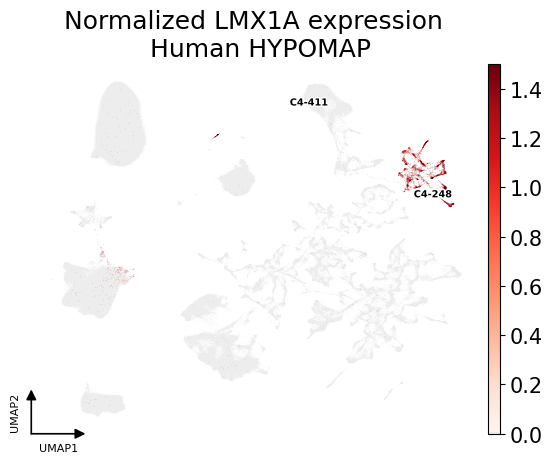

In [15]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText
from matplotlib.colors import LinearSegmentedColormap

base = plt.get_cmap("Reds")
colors = base(np.linspace(0, 1, 256))
colors[0] = mpl.colors.to_rgba("#ededed")  # force the very first color stop to light grey
cmap = LinearSegmentedColormap.from_list("bone_r_grey0", colors)

celltypes = ['C4-248', 'C4-411']
fig = sc.pl.embedding(
    adata,
    basis="X_umap",
    color="LMX1A",
    layer="norm",
    color_map=cmap,
    title="Normalized LMX1A expression \n Human HYPOMAP",
    return_fig=True,
    vmax=1.5)
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Compute centroid of each celltype in tSNE space and annotate
tsne_coords = adata.obsm["X_umap"]
texts = []
for ct in celltypes:
    mask = adata.obs["C4"] == ct
    if mask.sum() == 0:
        continue
    cx, cy = tsne_coords[mask].mean(axis=0)
    short = ct.replace("_", " ")
    t = ax.text(
        cx, cy, short,
        fontsize=7,
        fontweight="bold",
        ha="center", va="center",
        color="black",
        path_effects=[mpl.patheffects.withStroke(linewidth=2, foreground="white")]
    )
    texts.append(t)

# Move labels apart, drawing thin connector lines back to their original spot
adjustText.adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color='black', lw=1.0))

# Re-apply white-stroke outline (adjustText can reset path effects)
for t in texts:
    t.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])

# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'UMAP1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'UMAP2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Figure_4f.pdf", bbox_inches='tight', dpi=600)

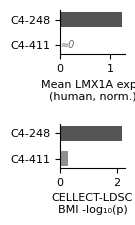

In [20]:
import scanpy as sc
import numpy as np
import pandas as pd
from scipy.sparse import issparse
import matplotlib.pyplot as plt

C4_TARGETS = ['C4-248', 'C4-411']
COL_HL   = '#555555'
COL_GREY = '#8E8E93'
target_colors = {'C4-248': COL_HL, 'C4-411': COL_GREY}

# ── 1. Find LMX1A in this object's var_names ──────────────────────────────────
human_gene = None
for candidate in ['LMX1A', 'Lmx1a', 'lmx1a']:
    if candidate in adata.var_names:
        human_gene = candidate
        break
if human_gene is None:
    matches = [g for g in adata.var_names if g.upper() == 'LMX1A']
    if matches:
        human_gene = matches[0]
if human_gene is None:
    raise ValueError("LMX1A not found in adata.var_names")

gene_idx = adata.var_names.get_loc(human_gene)
X_norm = adata.layers['norm']
lmx1a_expr = (np.asarray(X_norm[:, gene_idx].todense()).ravel()
              if issparse(X_norm)
              else np.asarray(X_norm[:, gene_idx]).ravel())
adata.obs['LMX1A_expr'] = lmx1a_expr

# ── 2. LMX1A expression per cluster ──────────────────────────────────────────
lmx1a_means = (adata.obs[adata.obs['C4'].isin(C4_TARGETS)]
               .groupby('C4', observed=True)['LMX1A_expr']
               .mean()
               .reindex(C4_TARGETS))

# ── 3. CELLECT-LDSC BMI p-values ─────────────────────────────────────────────
cellect = pd.read_csv("hypomap_cellect_unified.csv")
ldsc = cellect[
    (cellect['gwas']   == 'BMI_Yengo2018') &
    (cellect['level']  == 'C4') &
    (cellect['method'] == 'new_LDSC') &
    (cellect['cluster_id'].isin(C4_TARGETS))
].set_index('cluster_id').reindex(C4_TARGETS)
neg_log10_p = -np.log10(ldsc['pvalue'])

# ── 4. Two horizontal bar plots stacked vertically ───────────────────────────
# Order: C4-248 on top (index 1 in barh = top), C4-411 below
y      = np.arange(len(C4_TARGETS))[::-1]  # [1, 0] so C4-248 renders at top
colors = [target_colors[c] for c in C4_TARGETS]

fig, (ax_expr, ax_p) = plt.subplots(2, 1, figsize=(1.6, 2.5))

for ax, vals, xlabel in [
    (ax_expr, lmx1a_means.values,  'Mean LMX1A expr.\n(human, norm.)'),
    (ax_p,    neg_log10_p.values,   'CELLECT-LDSC\nBMI -log₁₀(p)'),
]:
    ax.barh(y, vals, color=colors, height=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(C4_TARGETS, fontsize=8)
    ax.set_xlabel(xlabel, fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=8)

    # Summary annotation for zero/near-zero bars (matching Figure_4b style)
    max_val = np.nanmax(vals)
    for i, (cid, val) in enumerate(zip(C4_TARGETS, vals)):
        if np.isnan(val) or val < max_val * 0.05:
            ax.text(max_val * 0.02, y[i], '≈0',
                    ha='left', va='center', fontsize=7,
                    style='italic', color='#666666')

plt.tight_layout()
plt.savefig("Figure_C4_248_411_bars.pdf", bbox_inches='tight')
plt.show()

Human C4-248 effectors  : 24 genes
Mouse 04_Crnde_Lmx1a effectors: 32 genes
Shared genes: 9


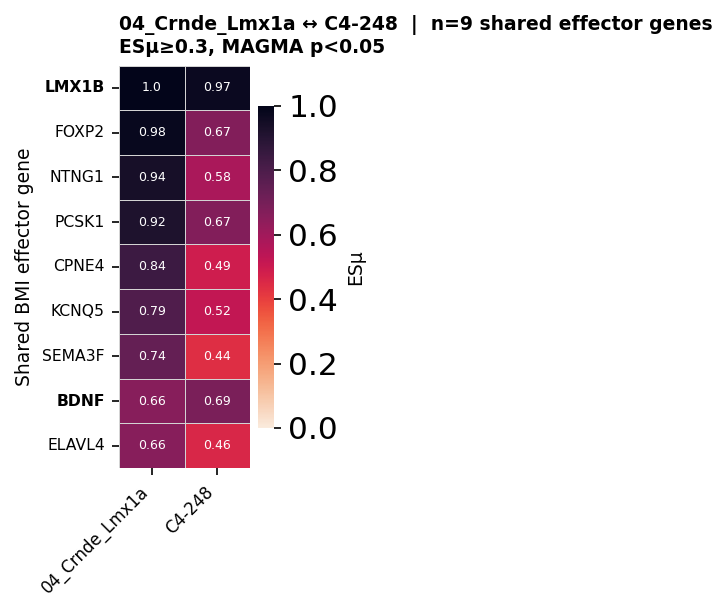

Saved cross-species heatmap (9 shared genes)


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

MOUSE_PATH = "detailed_celltype_annotation__BMI_Yengo2018.effector_genes.txt"
C4_PATH    = "named_c4__BMI_Yengo2018.effector_genes.txt"
ESM_MIN  = 0.3
MAGMA_P  = 0.05
MOUSE_TARGET = '04_Crnde_Lmx1a'
C4_TARGET    = 'C4-248'
BOLD = {'BDNF', 'LMX1B'}

plt.rcParams.update({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'figure.dpi': 150, 'savefig.dpi': 300,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})

cmap = sns.color_palette("rocket_r", as_cmap=True)
cmap.set_bad(color='lightgray')

# ── 1. Load + parse human C4 effector file ────────────────────────────────────
eff_c4 = pd.read_csv(C4_PATH, sep='\t')
eff_c4['cluster_id'] = eff_c4['annotation'].str.extract(r'^C4_(\d+)').apply(
    lambda x: 'C4-' + x[0] if pd.notna(x[0]) else np.nan, axis=1)
if C4_TARGET not in eff_c4['cluster_id'].values:
    raise ValueError(f"{C4_TARGET} not found in {C4_PATH} — check cluster_id parsing")

human_filt = eff_c4[
    (eff_c4['cluster_id'] == C4_TARGET) &
    (eff_c4['esmu'] >= ESM_MIN) &
    (eff_c4['magma_gene_pval'] < MAGMA_P)
].copy()

# ── 2. Load + parse mouse effector file ───────────────────────────────────────
eff_mouse = pd.read_csv(MOUSE_PATH, sep='\t')
if MOUSE_TARGET not in eff_mouse['annotation'].values:
    raise ValueError(f"{MOUSE_TARGET} not found in {MOUSE_PATH} — check annotation values")

mouse_filt = eff_mouse[
    (eff_mouse['annotation'] == MOUSE_TARGET) &
    (eff_mouse['esmu'] >= ESM_MIN) &
    (eff_mouse['magma_gene_pval'] < MAGMA_P)
].copy()

print(f"Human {C4_TARGET} effectors  : {human_filt['gene_symbol'].nunique()} genes")
print(f"Mouse {MOUSE_TARGET} effectors: {mouse_filt['gene_symbol'].nunique()} genes")

# ── 3. Shared effector genes only ─────────────────────────────────────────────
human_genes = set(human_filt['gene_symbol'])
mouse_genes = set(mouse_filt['gene_symbol'])
shared      = human_genes & mouse_genes
print(f"Shared genes: {len(shared)}")

def gene_max_esmu(g):
    vals = [human_filt.loc[human_filt['gene_symbol'] == g, 'esmu'].max(),
            mouse_filt.loc[mouse_filt['gene_symbol'] == g, 'esmu'].max()]
    return max(vals)

gene_order = sorted(shared, key=lambda g: -gene_max_esmu(g))

# ── 4. Build matrix: rows = cell types, cols = genes, then transpose ──────────
mat = pd.DataFrame(index=[MOUSE_TARGET, C4_TARGET], columns=gene_order, dtype=float)
mat.loc[MOUSE_TARGET] = mouse_filt.set_index('gene_symbol')['esmu'].reindex(gene_order)
mat.loc[C4_TARGET]    = human_filt.set_index('gene_symbol')['esmu'].reindex(gene_order)
mat = mat.T   # genes as rows, cell types as columns

fig_h = max(2, len(gene_order) * 0.35 + 1.0)
fig, ax = plt.subplots(figsize=(2.5, fig_h))

sns.heatmap(mat, ax=ax,
            cmap=cmap, vmin=0, vmax=1.0,
            linewidths=0.35, linecolor='lightgrey',
            mask=mat.isna(),
            xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'ESµ', 'shrink': 0.8},
            annot=mat.round(2), fmt='', annot_kws={'fontsize': 6})

ax.set_xticklabels(ax.get_xticklabels(), fontsize=8, rotation=45, ha='right')
for tick in ax.get_yticklabels():
    tick.set_fontsize(7.5)
    tick.set_fontweight('bold' if tick.get_text().upper() in BOLD else 'normal')
    tick.set_rotation(0)

ax.set_ylabel('Shared BMI effector gene', fontsize=9)
ax.set_xlabel('')
ax.set_title(f'{MOUSE_TARGET} ↔ {C4_TARGET}  |  n={len(gene_order)} shared effector genes\n'
             f'ESµ≥{ESM_MIN}, MAGMA p<{MAGMA_P}',
             fontweight='bold', fontsize=9, loc='left')

plt.tight_layout()
plt.savefig('effector_crossspecies_04_C4248_shared.pdf', bbox_inches='tight')
plt.show()
print(f"Saved cross-species heatmap ({len(gene_order)} shared genes)")

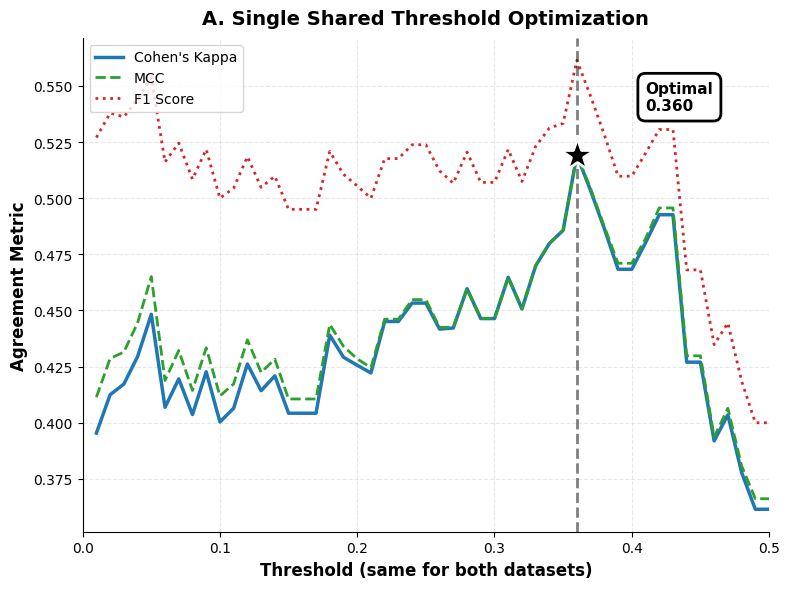

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec
# Load the CSV files
df_single = pd.read_csv('threshold_optimization_single.csv')
df_grid = pd.read_csv('threshold_optimization_grid.csv')
# Single Shared Threshold Optimization
fig, ax_a = plt.subplots(figsize=(8, 6))
# Define colors
color_kappa = '#1f77b4'  # Blue
color_mcc = '#2ca02c'    # Green
color_f1 = '#d62728'     # Red
color_current = '#bcbcbc'  # Gray
color_optimal = 'black'

# Current and optimal thresholds
current_threshold = 0.1
optimal_threshold = 0.36

# Find closest matches (to handle floating point precision)
idx_current = (df_single['threshold'] - current_threshold).abs().idxmin()
idx_optimal = (df_single['threshold'] - optimal_threshold).abs().idxmin()

current_kappa = df_single.loc[idx_current, 'kappa']
current_agreement = df_single.loc[idx_current, 'agreement'] * 100

optimal_kappa_single = df_single.loc[idx_optimal, 'kappa']
optimal_agreement_single = df_single.loc[idx_optimal, 'agreement'] * 100

# Find optimal from grid (max kappa)
optimal_grid_idx = df_grid['kappa'].idxmax()
optimal_sc = df_grid.loc[optimal_grid_idx, 'sc_threshold']
optimal_spatial = df_grid.loc[optimal_grid_idx, 'spatial_threshold']
optimal_kappa_grid = df_grid.loc[optimal_grid_idx, 'kappa']
optimal_agreement_grid = df_grid.loc[optimal_grid_idx, 'agreement'] * 100

# Plot metrics
ax_a.plot(df_single['threshold'], df_single['kappa'], 
         color=color_kappa, linewidth=2.5, label="Cohen's Kappa")
ax_a.plot(df_single['threshold'], df_single['mcc'], 
         color=color_mcc, linewidth=2, linestyle='--', label='MCC')
ax_a.plot(df_single['threshold'], df_single['f1'], 
         color=color_f1, linewidth=2, linestyle=':', label='F1 Score')

# Mark optimal threshold
ax_a.axvline(optimal_threshold, color=color_optimal, linestyle='--', 
            linewidth=2, alpha=0.5)
ax_a.plot(optimal_threshold, optimal_kappa_single, marker='*', 
         markersize=25, color=color_optimal, zorder=10, 
         markeredgecolor='white', markeredgewidth=2)

# Annotation for optimal
ax_a.annotate(f'Optimal\n{optimal_threshold:.3f}', 
             xy=(optimal_threshold, optimal_kappa_single),
             xytext=(optimal_threshold + 0.05, optimal_kappa_single + 0.02),
             fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', 
                      edgecolor='black', linewidth=2))

ax_a.set_xlabel('Threshold (same for both datasets)', fontsize=12, fontweight='bold')
ax_a.set_ylabel('Agreement Metric', fontsize=12, fontweight='bold')
ax_a.set_title('A. Single Shared Threshold Optimization', fontsize=14, fontweight='bold', pad=10)
ax_a.legend(loc='upper left', frameon=True, fontsize=10)
ax_a.grid(alpha=0.3, linestyle='--')
ax_a.set_xlim(0, 0.5)
ax_a.spines['top'].set_visible(False)
ax_a.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('Supplementary_Figure_1.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
adata_mouse = sc.read("allgenes_bipca_annotated.h5ad")
adata_mouse

AnnData object with n_obs × n_vars = 193989 × 22180
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'old.ident', 'hash.mcl.ID', 'seurat_clusters', 'sex', 'area', 'lane', 'sort', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'detailed_celltype_annotation', 'leiden', 'size_factors', 'cellect_bmi_manual', 'cellect_bmi_detailed', 'cellect_bmi_manual_BH', 'cellect_bmi_detailed_BH', 'manual_significant_BH', 'detailed_significant_BH', 'AAV', 'AAV_ratio', 'cellect_bmi_log10', 'region_collapsed', 'score_region_collapsed', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'region_collapsed_filtered', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'plot', 'neurotransmitter'
    var: 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'AAV_colors', 'bipca', 'cellect_bmi_manual_colors', 'dendrogram_detailed_celltype_annotation', 'detailed_celltype_annotation_col

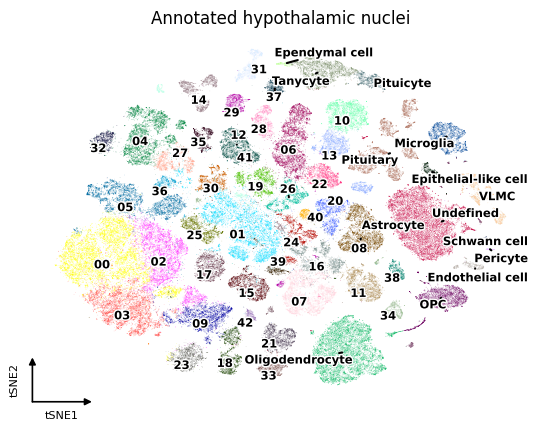

In [8]:
import re
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText

# ── 1. Build short labels ─────────────────
def transform_label(label):
    if re.match(r'^\d', label):
        return label.split('_')[0]
    elif 'Pituitary' in label:
        return 'Pituitary'
    else:
        return label.replace('_', ' ')

adata_mouse.obs['label_short'] = (
    adata_mouse.obs['detailed_celltype_annotation']
    .astype(str)
    .map(transform_label)
)


fig = sc.pl.embedding(
    adata_mouse,
    basis="tsne",
    color="label_short",
    legend_loc="on data",
    legend_fontsize="small",
    alpha=0.5,
    return_fig=True,
    title="Annotated hypothalamic nuclei")
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Add white outline to all text labels for contrast
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
adjustText.adjust_text(
    ax.texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color='black', lw=1.5))
# Re-apply path effects after adjustText (it may reset them)
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
    
# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Supplementary_Figure_2a.pdf", bbox_inches='tight', dpi=600)
plt.show()

In [3]:
#del adata
adata = sc.read("neurons_bipca_leiden.h5ad")
adata

AnnData object with n_obs × n_vars = 131970 × 21596
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'old.ident', 'hash.mcl.ID', 'seurat_clusters', 'sex', 'area', 'lane', 'sort', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'detailed_celltype_annotation', 'leiden', 'size_factors', 'cellect_bmi_manual', 'cellect_bmi_detailed', 'cellect_bmi_manual_BH', 'cellect_bmi_detailed_BH', 'manual_significant_BH', 'detailed_significant_BH', 'AAV', 'AAV_ratio', 'cellect_bmi_log10', 'region_collapsed', 'score_region_collapsed', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'region_collapsed_filtered', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'plot', 'neurotransmitter', 'viral_zscore_animal', 'viral_zscore_animal_capped', 'virus_positive', 'celltype_HM', 'score_celltype_HM', 'region_HM', 'score_region_HM', 'C1_HM', 'score_C1_HM', 'C2_HM', 'score_C2_HM', 'C3_HM', 'score_C3_HM', 'C4_HM', 'score_C4_HM', 'region_HM_

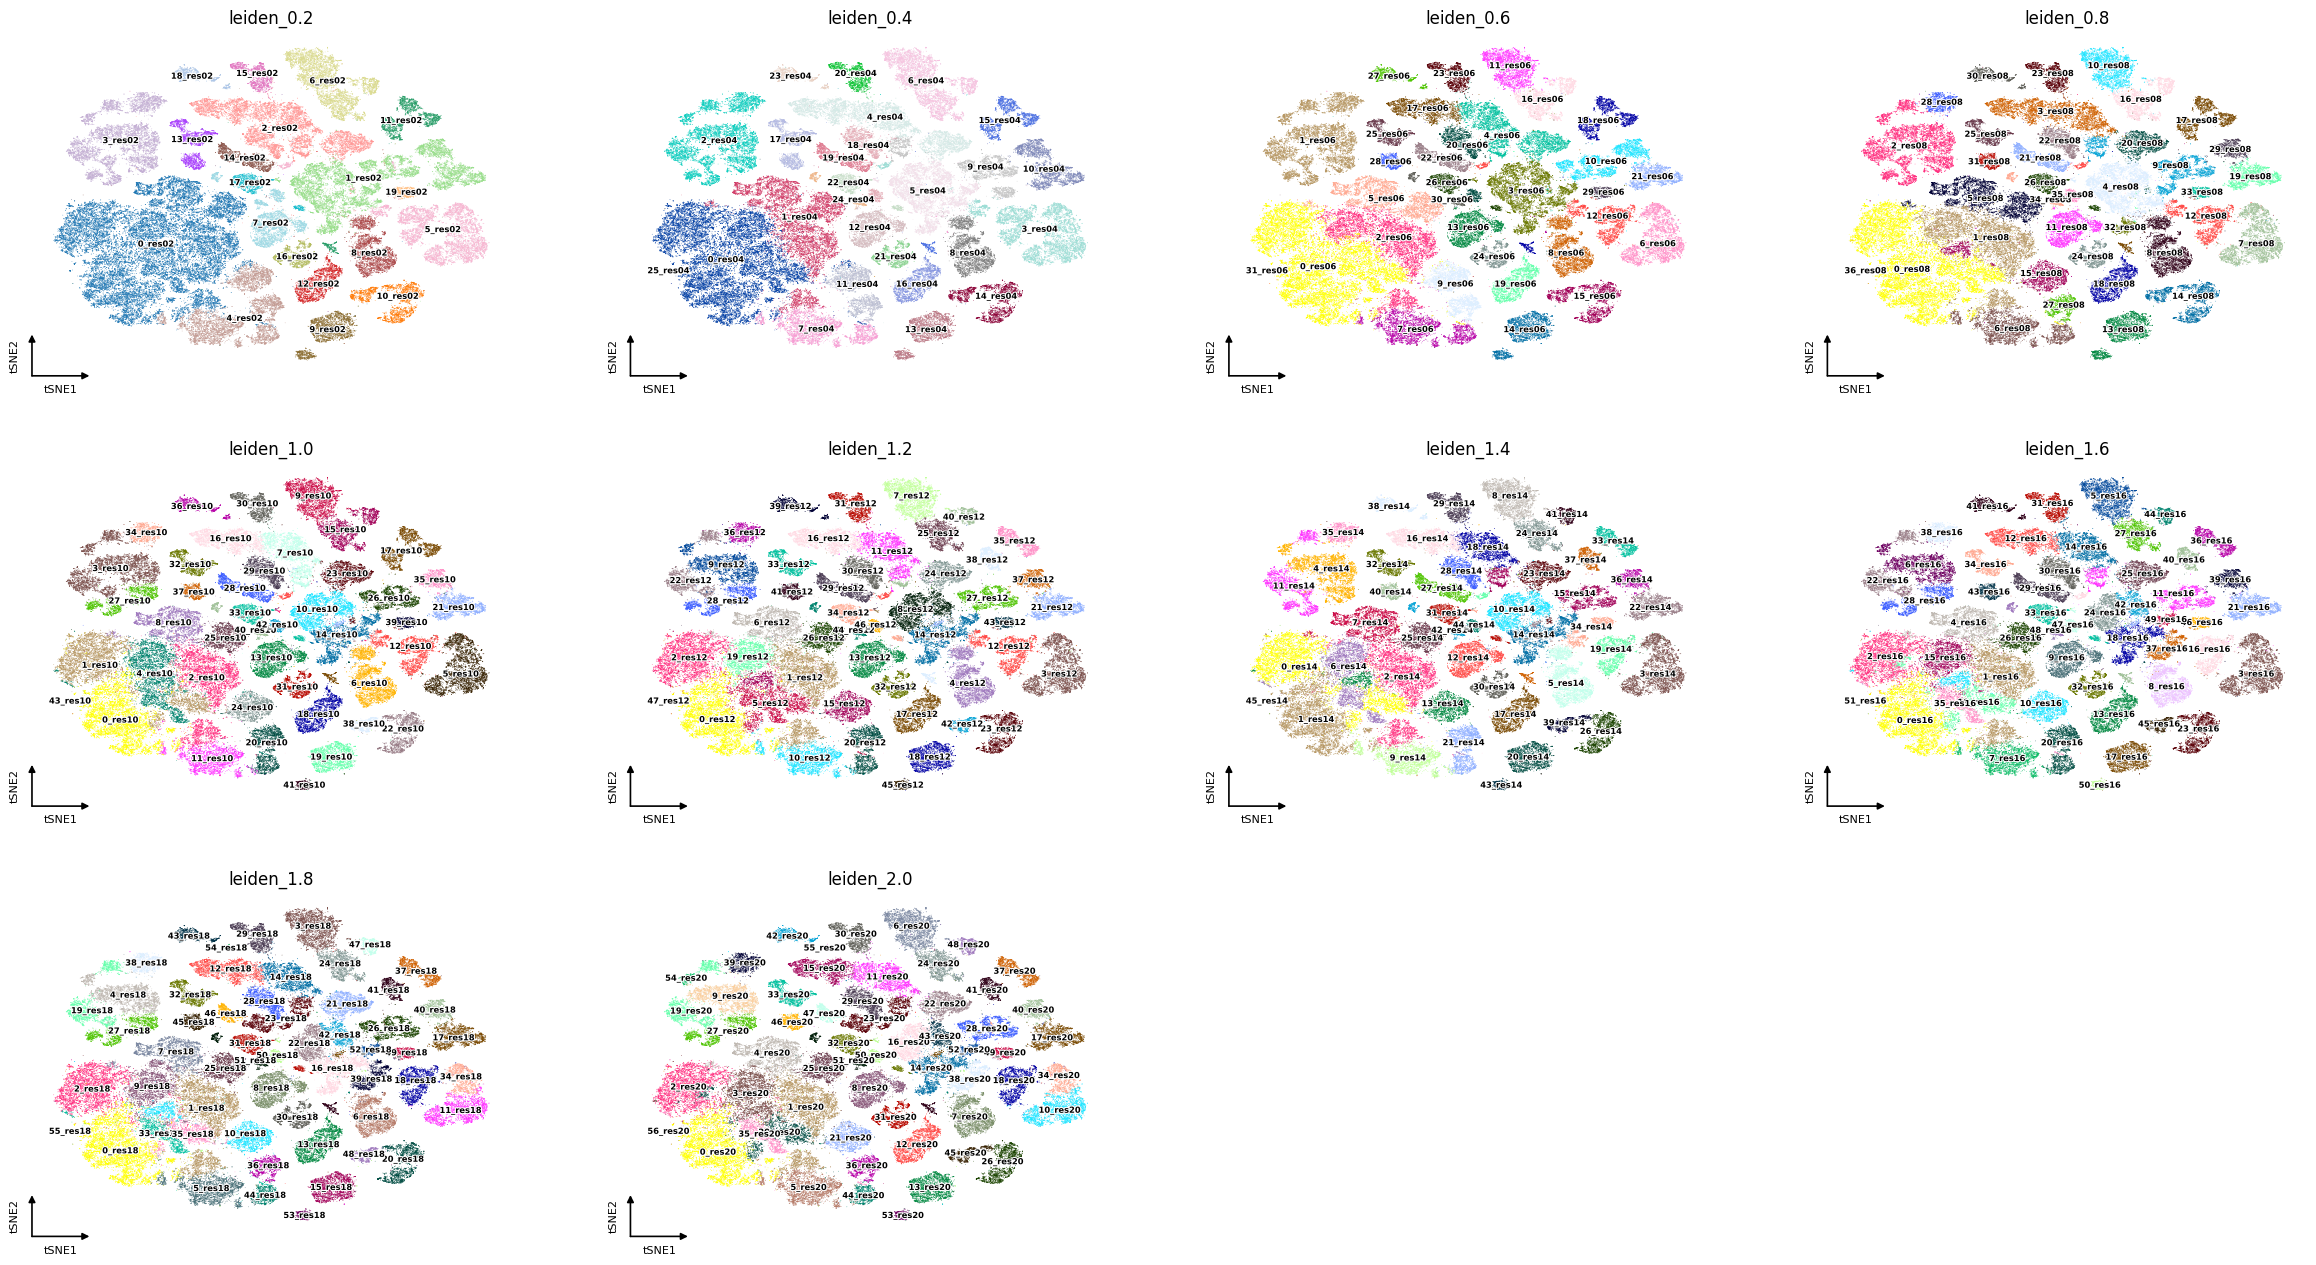

In [5]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText

leiden = ['leiden_0.2', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0',
          'leiden_1.2', 'leiden_1.4', 'leiden_1.6', 'leiden_1.8', 'leiden_2.0']

fig = sc.pl.embedding(
    adata,
    basis='tsne',
    color=leiden,
    legend_loc='on data',
    legend_fontsize='small',
    return_fig=True,
)

arrow_len = 0.12

for ax in fig.axes:
    # Rasterize scatter, keep labels/arrows as vectors
    for col in ax.collections:
        col.set_rasterized(True)

    # Apply white stroke to native scanpy on-data labels
    for t in ax.texts:
        t.set_fontsize(6)
        t.set_path_effects([mpl.patheffects.withStroke(linewidth=1.5, foreground='white')])

    # Remove frame
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    # tSNE axis arrows
    for (x0, y0), (x1, y1) in [((0,0),(arrow_len,0)), ((0,0),(0,arrow_len))]:
        ax.annotate('', xy=(x1, y1), xytext=(x0, y0),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                                    shrinkA=0, shrinkB=0))
    ax.text(arrow_len/2, -0.025, 'tSNE1', transform=ax.transAxes,
            ha='center', va='top', fontsize=8)
    ax.text(-0.025, arrow_len/2, 'tSNE2', transform=ax.transAxes,
            ha='right', va='center', fontsize=8, rotation=90)

plt.savefig('Supplementary_Figure_3a.pdf', bbox_inches='tight', dpi=600)
plt.show()

/scratch/tmp.5904923.bcoester/ipykernel_3357448/3010106271.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(adata.obs[res_label]).mean())
/scratch/tmp.5904923.bcoester/ipykernel_3357448/3010106271.py:42: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g["esmu"].corr(g["bmi_neglog10"]))
/scratch/tmp.5904923.bcoester/ipykernel_3357448/3010106271.py:46: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of

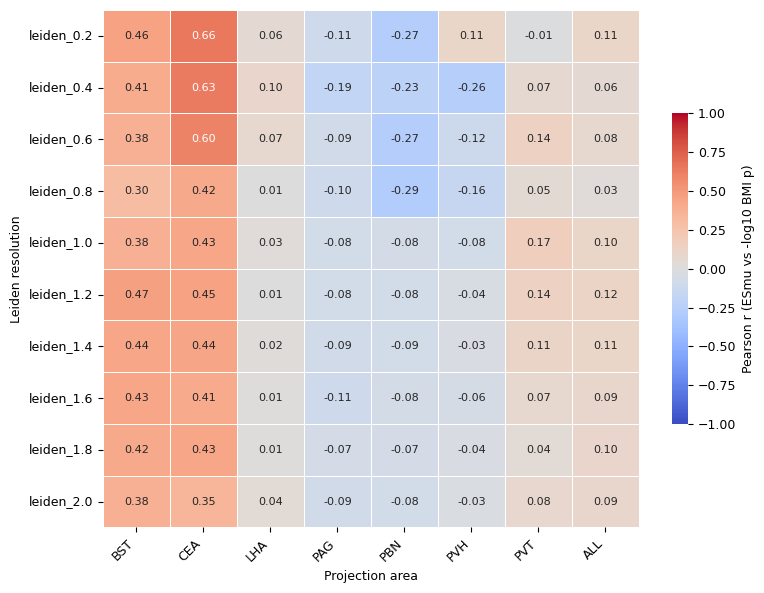

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ── 1. Load CELLEX ESmu (v147 row) for all area x resolution files ────────────
indir = "leiden_cellex_results"
records = []
for fn in os.listdir(indir):
    if not fn.endswith("_cellex.csv") or "_leiden_" not in fn:
        continue
    base  = fn[:-len("_cellex.csv")]
    area, leiden_part = base.split("_leiden_", 1)
    res   = f"leiden_{leiden_part.replace('_', '.')}"
    df    = pd.read_csv(os.path.join(indir, fn), index_col=0)
    if "v147" not in df.index:
        continue
    for cluster, esmu in df.loc["v147"].items():
        records.append({"area": area, "resolution": res, "cluster": cluster, "esmu": esmu})

combined_long = pd.DataFrame(records)

# ── 2. Load per-cell BMI -log10(p) from adata.obs and average per cluster ─────
resolutions = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
bmi_records = []
for res in resolutions:
    res_label = f"leiden_{res}"
    bmi_per_cluster = (adata.obs[f"BMI_{res_label}_log10"]
                       .groupby(adata.obs[res_label]).mean())
    for cluster, bmi in bmi_per_cluster.items():
        bmi_records.append({"resolution": res_label, "cluster": cluster, "bmi_neglog10": bmi})

bmi_long = pd.DataFrame(bmi_records)

# ── 3. Merge and compute Pearson r per (resolution x area) ───────────────────
df_plot = combined_long.merge(bmi_long, on=["resolution", "cluster"], how="inner")

corr_table = (df_plot
              .groupby(["resolution", "area"])
              .apply(lambda g: g["esmu"].corr(g["bmi_neglog10"]))
              .unstack("area"))
corr_table["ALL"] = (df_plot
                     .groupby("resolution")
                     .apply(lambda g: g["esmu"].corr(g["bmi_neglog10"])))

# ── 4. Heatmap ────────────────────────────────────────────────────────────────
mpl.rcParams.update({'font.size': 9, 'pdf.fonttype': 42})

fig, ax = plt.subplots(figsize=(len(corr_table.columns) * 0.8 + 1.5,
                                len(corr_table) * 0.5 + 1.0))
sns.heatmap(
    corr_table,
    ax=ax,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    linewidths=0.4, linecolor="white",
    cbar_kws={"label": "Pearson r (ESmu vs -log10 BMI p)", "shrink": 0.6},
)
ax.set_xlabel("Projection area")
ax.set_ylabel("Leiden resolution")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig("Supplementary_Figure_3b.pdf", bbox_inches="tight", dpi=300)
plt.show()

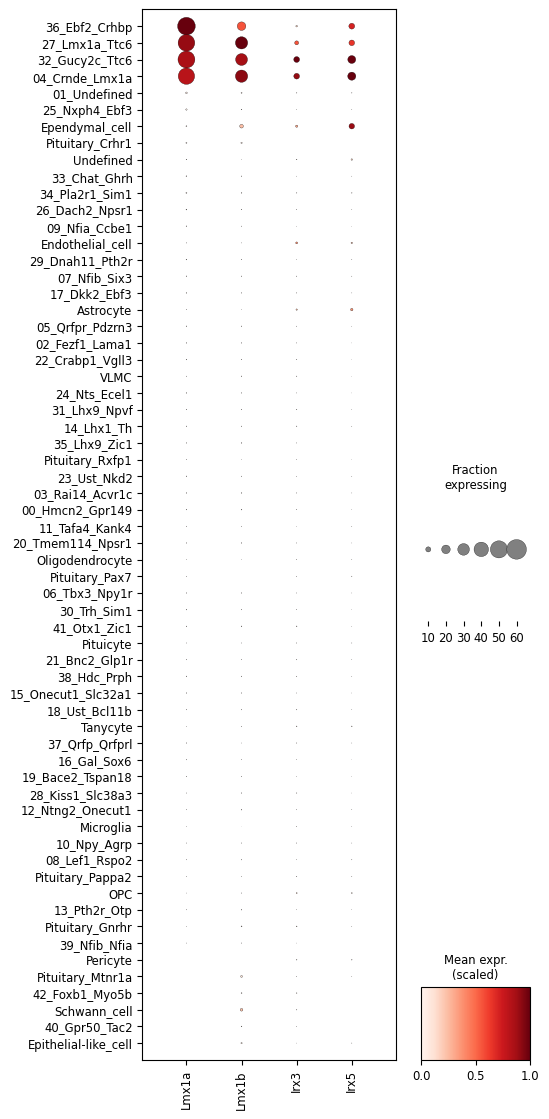

In [18]:
import re
import numpy as np

GENES = ['Lmx1a', 'Lmx1b', 'Irx3', 'Irx5']

# Order cell types by mean Lmx1a expression
adata_mouse.X = adata_mouse.layers['scran_normalization']
lmx1a_mean = (
    adata_mouse[:, 'Lmx1a'].X.toarray().ravel()
    if hasattr(adata_mouse[:, 'Lmx1a'].X, 'toarray')
    else np.asarray(adata_mouse[:, 'Lmx1a'].X).ravel()
)
import pandas as pd
ct_order = (
    pd.Series(lmx1a_mean, index=adata_mouse.obs['detailed_celltype_annotation'])
    .groupby(level=0).mean()
    .sort_values(ascending=False)
    .index.tolist()
)

sc.pl.dotplot(
    adata_mouse,
    var_names=GENES,
    groupby='detailed_celltype_annotation',
    categories_order=ct_order,
    layer='scran_normalization',
    standard_scale='var',   # scale each gene 0-1 across clusters for comparability
    colorbar_title='Mean expr.\n(scaled)',
    size_title='Fraction\nexpressing',
    figsize=(5, len(ct_order) * 0.22),
    swap_axes=False,        # genes as columns, cell types as rows
    save='Supplementary_Figure_4a.pdf'
)

Lmx1a > 0.1, label score >= 0.4, frac ~ region + (1|animal):
                 region      coef  mean_frac  n_animals          padj   sig
   retromammillary_area  0.433526   0.476543         15 4.822295e-131  True
 posterior_hypothalamus  0.258988   0.292191         56 5.848063e-116  True
  premammillary_nucleus  0.224112   0.257891         55  1.820098e-86  True
               midbrain  0.031201   0.065639         11  1.523494e-01 False
               thalamus -0.002787   0.030711         57  8.038053e-01 False
     mammillary_nucleus -0.003976   0.028889         51  7.871945e-01 False
suprachiasmatic_nucleus -0.015332   0.017623         30  3.034918e-01 False
medial_preoptic_nucleus -0.019655   0.012864         47  1.353581e-01 False
  anterior_hypothalamus -0.020481   0.013017         57  1.188887e-01 False
           zona_incerta -0.022291   0.009500         38  1.200156e-01 False
   ventromedial_nucleus -0.023711   0.009787         57  6.914800e-02 False
    dorsomedial_nucleus -0.

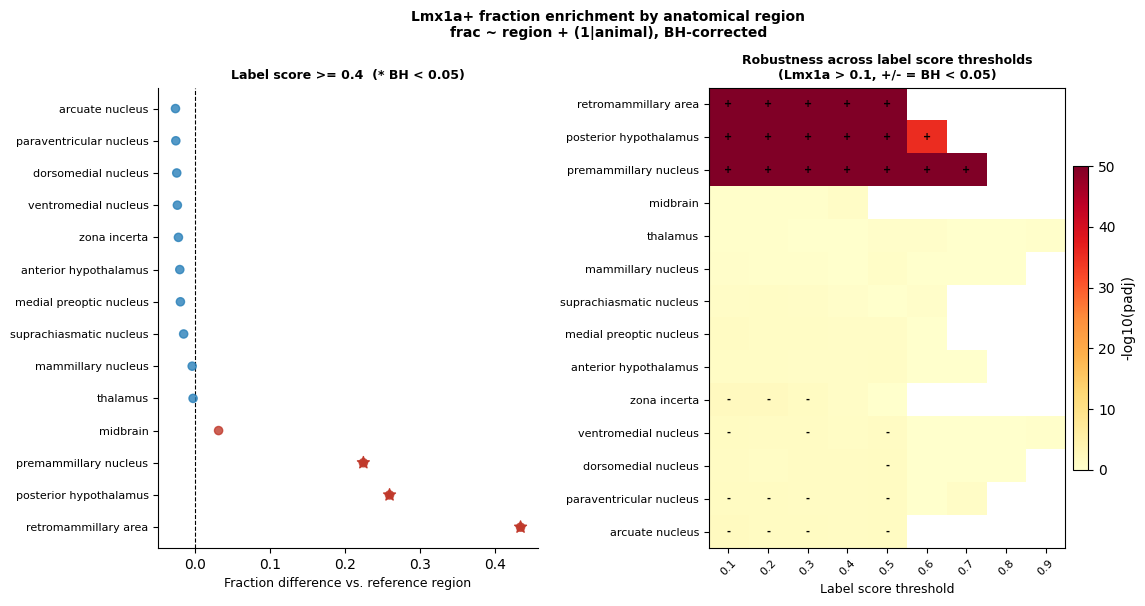

In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore')

# ── 1. Extract Lmx1a expression ──────────────────────────────────────────────
gene = 'Lmx1a'
idx  = adata_mouse.var_names.get_loc(gene)
X    = adata_mouse.layers['scran_normalization']
expr = (X[:, idx].toarray().ravel() if issparse(X)
        else np.asarray(X[:, idx]).ravel())

df = adata_mouse.obs[['hash.mcl.ID', 'region_collapsed', 'score_region_collapsed']].copy()
df['expr'] = expr
df = df.dropna(subset=['region_collapsed', 'hash.mcl.ID'])
df = df[~df['region_collapsed'].isin(['undefined', 'NA'])]
df.rename(columns={'hash.mcl.ID': 'animal'}, inplace=True)

EXPR_THRESH   = 0.1                                             # fixed
SCORE_THRESHS = [round(x, 1) for x in np.arange(0.1, 1.0, 0.1)]  # 0.1 to 0.9

# ── 2. Single mixed model per score threshold ─────────────────────────────────
# frac_Lmx1a+ ~ C(region) + (1|animal), one fit per score threshold
records = []

for score_thresh in SCORE_THRESHS:
    sub = df[df['score_region_collapsed'] >= score_thresh].copy()
    sub['pos'] = (sub['expr'] > EXPR_THRESH).astype(float)

    pb = (sub.groupby(['animal', 'region_collapsed'], observed=True)
             .agg(n_pos=('pos', 'sum'), n_total=('pos', 'count'))
             .reset_index())
    pb['frac'] = pb['n_pos'] / pb['n_total']
    pb = pb[pb['n_total'] >= 10]

    region_counts = pb.groupby('region_collapsed')['animal'].nunique()
    valid = region_counts[region_counts >= 3].index
    pb = pb[pb['region_collapsed'].isin(valid)].copy()

    if pb['region_collapsed'].nunique() < 3:
        print(f'  score={score_thresh}: too few regions after filtering, skipping')
        continue

    n_cells = len(sub)
    ref = pb.groupby('region_collapsed')['n_total'].sum().idxmax()
    pb['region_collapsed'] = pd.Categorical(
        pb['region_collapsed'],
        categories=[ref] + [r for r in valid if r != ref])

    try:
        fit = smf.mixedlm('frac ~ C(region_collapsed)', pb,
                           groups=pb['animal']).fit(reml=True, disp=False)
    except Exception as e:
        print(f'  score={score_thresh}: fit failed ({e})')
        continue

    for term in fit.params.index:
        if not term.startswith('C(region_collapsed)'):
            continue
        region = term.replace('C(region_collapsed)[T.', '').rstrip(']')
        records.append({
            'score_thresh': score_thresh,
            'region':       region,
            'coef':         fit.params[term],
            'pval':         fit.pvalues[term],
            'mean_frac':    pb.loc[pb['region_collapsed'] == region, 'frac'].mean(),
            'n_animals':    pb.loc[pb['region_collapsed'] == region, 'animal'].nunique(),
            'n_cells_total': n_cells,
        })

results = pd.DataFrame(records)

def bh_correct(g):
    g = g.copy()
    _, padj, _, _ = multipletests(g['pval'], method='fdr_bh')
    g['padj'] = padj
    return g

results = (results.groupby('score_thresh', group_keys=False).apply(bh_correct))
results['sig'] = results['padj'] < 0.05
results['up']  = results['coef'] > 0

# ── 3. Primary result at score >= 0.4 ────────────────────────────────────────
primary = results[results['score_thresh'] == 0.4]
print(f'Lmx1a > {EXPR_THRESH}, label score >= 0.4, frac ~ region + (1|animal):')
print(primary.sort_values('coef', ascending=False)
      [['region','coef','mean_frac','n_animals','padj','sig']].to_string(index=False))

# ── 4. Figure ─────────────────────────────────────────────────────────────────
# Region order from primary result
region_order = primary.sort_values('coef', ascending=False)['region'].tolist()

fig, (ax_dot, ax_heat) = plt.subplots(
    1, 2, figsize=(12, max(4, len(region_order) * 0.32 + 1.5)),
    gridspec_kw={'wspace': 0.45})

# Dot plot: primary threshold only, coefficient per region
sig_mask  = primary.set_index('region').reindex(region_order)['sig'].fillna(False).values
coef_vals = primary.set_index('region').reindex(region_order)['coef'].values
colors    = np.where(primary.set_index('region').reindex(region_order)['up'].fillna(False),
                     '#C0392B', '#2980B9')

ax_dot.scatter(coef_vals, range(len(region_order)), c=colors, s=35, zorder=3, alpha=0.8)
ax_dot.scatter(coef_vals[sig_mask], np.where(sig_mask)[0],
               c=np.array(colors)[sig_mask], s=80, zorder=4, marker='*')
ax_dot.axvline(0, color='black', lw=0.8, ls='--')
ax_dot.set_yticks(range(len(region_order)))
ax_dot.set_yticklabels([r.replace('_', ' ') for r in region_order], fontsize=8)
ax_dot.set_xlabel('Fraction difference vs. reference region', fontsize=9)
ax_dot.set_title(f'Label score >= 0.4  (* BH < 0.05)', fontsize=9, fontweight='bold')
ax_dot.spines['top'].set_visible(False)
ax_dot.spines['right'].set_visible(False)

# Heatmap: -log10(padj) across score thresholds, rows = regions, cols = thresholds
tested_threshs = sorted(results['score_thresh'].unique())
heat = pd.DataFrame(index=region_order, columns=tested_threshs, dtype=float)
for sth in tested_threshs:
    sub = results[results['score_thresh'] == sth].set_index('region')
    for r in region_order:
        if r in sub.index:
            heat.loc[r, sth] = min(-np.log10(sub.loc[r, 'padj'] + 1e-320), 50)

im = ax_heat.imshow(heat.values.astype(float), aspect='auto',
                    cmap='YlOrRd', vmin=0,
                    vmax=max(3, np.nanmax(heat.values.astype(float))))
for i, r in enumerate(region_order):
    for j, sth in enumerate(tested_threshs):
        sub = results[results['score_thresh'] == sth].set_index('region')
        if r in sub.index and sub.loc[r, 'sig']:
            ax_heat.text(j, i, '+' if sub.loc[r, 'up'] else '-',
                         ha='center', va='center', fontsize=7, fontweight='bold')

ax_heat.set_xticks(range(len(tested_threshs)))
ax_heat.set_xticklabels([str(s) for s in tested_threshs], fontsize=8, rotation=45)
ax_heat.set_yticks(range(len(region_order)))
ax_heat.set_yticklabels([r.replace('_', ' ') for r in region_order], fontsize=8)
ax_heat.set_xlabel('Label score threshold', fontsize=9)
ax_heat.set_title('Robustness across label score thresholds\n(Lmx1a > 0.1, +/- = BH < 0.05)',
                  fontsize=9, fontweight='bold')
plt.colorbar(im, ax=ax_heat, fraction=0.04, pad=0.02, label='-log10(padj)')

plt.suptitle('Lmx1a+ fraction enrichment by anatomical region\n'
             'frac ~ region + (1|animal), BH-corrected',
             fontsize=10, fontweight='bold', y=1.01)
plt.savefig('Supplementary_Figure_4b.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [10]:
adata = sc.read("LMX_bipca.h5ad")
adata

/cluster/home/bcoester/miniconda3/envs/bipca_env/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 11397 × 15916
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'old.ident', 'hash.mcl.ID', 'seurat_clusters', 'sex', 'area', 'lane', 'sort', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'detailed_celltype_annotation', 'leiden', 'size_factors', 'cellect_bmi_manual', 'cellect_bmi_detailed', 'cellect_bmi_manual_BH', 'cellect_bmi_detailed_BH', 'manual_significant_BH', 'detailed_significant_BH', 'AAV', 'AAV_ratio', 'cellect_bmi_log10', 'region_collapsed', 'score_region_collapsed', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'region_collapsed_filtered', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'plot', 'neurotransmitter', 'viral_zscore_animal', 'viral_zscore_animal_capped', 'virus_positive', 'celltype_HM', 'score_celltype_HM', 'region_HM', 'score_region_HM', 'C1_HM', 'score_C1_HM', 'C2_HM', 'score_C2_HM', 'C3_HM', 'score_C3_HM', 'C4_HM', 'score_C4_HM', 'region_HM_f

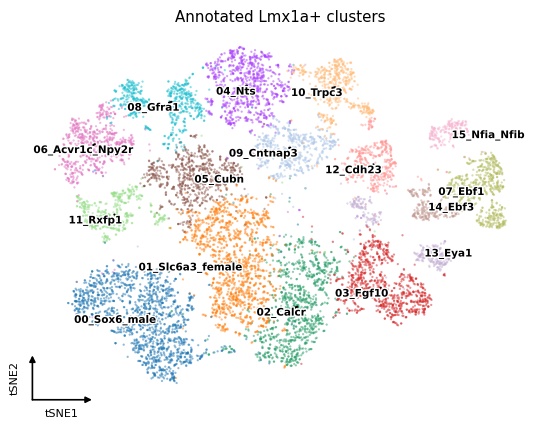

In [12]:
import re
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import adjustText

fig = sc.pl.embedding(
    adata,
    basis="tsne",
    color="subset_celltype_annotation",
    legend_loc="on data",
    legend_fontsize="small",
    alpha=0.5,
    return_fig=True,
    title="Annotated Lmx1a+ clusters")
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Add white outline to all text labels for contrast
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
adjustText.adjust_text(
    ax.texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color='black', lw=1.5))
# Re-apply path effects after adjustText (it may reset them)
for text in ax.texts:
    text.set_path_effects([
        mpl.patheffects.withStroke(linewidth=2, foreground='white')
    ])
    
# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)

plt.savefig("Supplementary_Figure_4c.pdf", bbox_inches='tight', dpi=600)
plt.show()

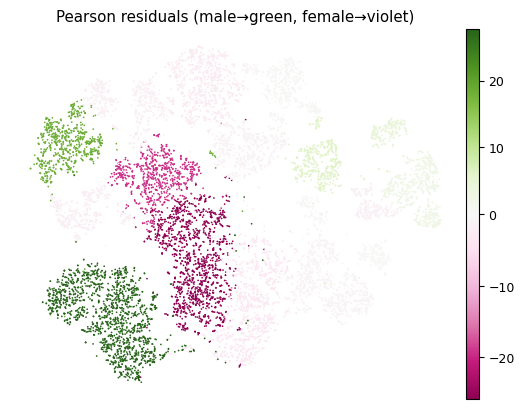

In [14]:
from matplotlib.colors import TwoSlopeNorm
sc.pl.embedding(
    adata,
    basis='tsne',
    color='sex_bias',
    cmap='PiYG',                    
    vcenter=0,
    size=6,
    frameon=False,
    title='Pearson residuals (male→green, female→violet)',
    return_fig=True
)
ax = fig.axes[0]
# Rasterize the scatter points only — keeps labels/arrows as vectors
for collection in ax.collections:
    collection.set_rasterized(True)
# Remove border/spines and ticks
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
# Small generic tSNE axis annotation in the bottom-left corner
arrow_len = 0.12   # fraction of axes
ax.annotate('', xy=(arrow_len, 0), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.annotate('', xy=(0, arrow_len), xytext=(0, 0),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                             shrinkA=0, shrinkB=0))
ax.text(arrow_len / 2, -0.025, 'tSNE1', transform=ax.transAxes,
        ha='center', va='top', fontsize=8)
ax.text(-0.025, arrow_len / 2, 'tSNE2', transform=ax.transAxes,
        ha='right', va='center', fontsize=8, rotation=90)
plt.savefig("Supplementary_Figure_4d.pdf", bbox_inches='tight', dpi=600)
plt.show()

Human: 24  Mouse: 32  Shared: 9


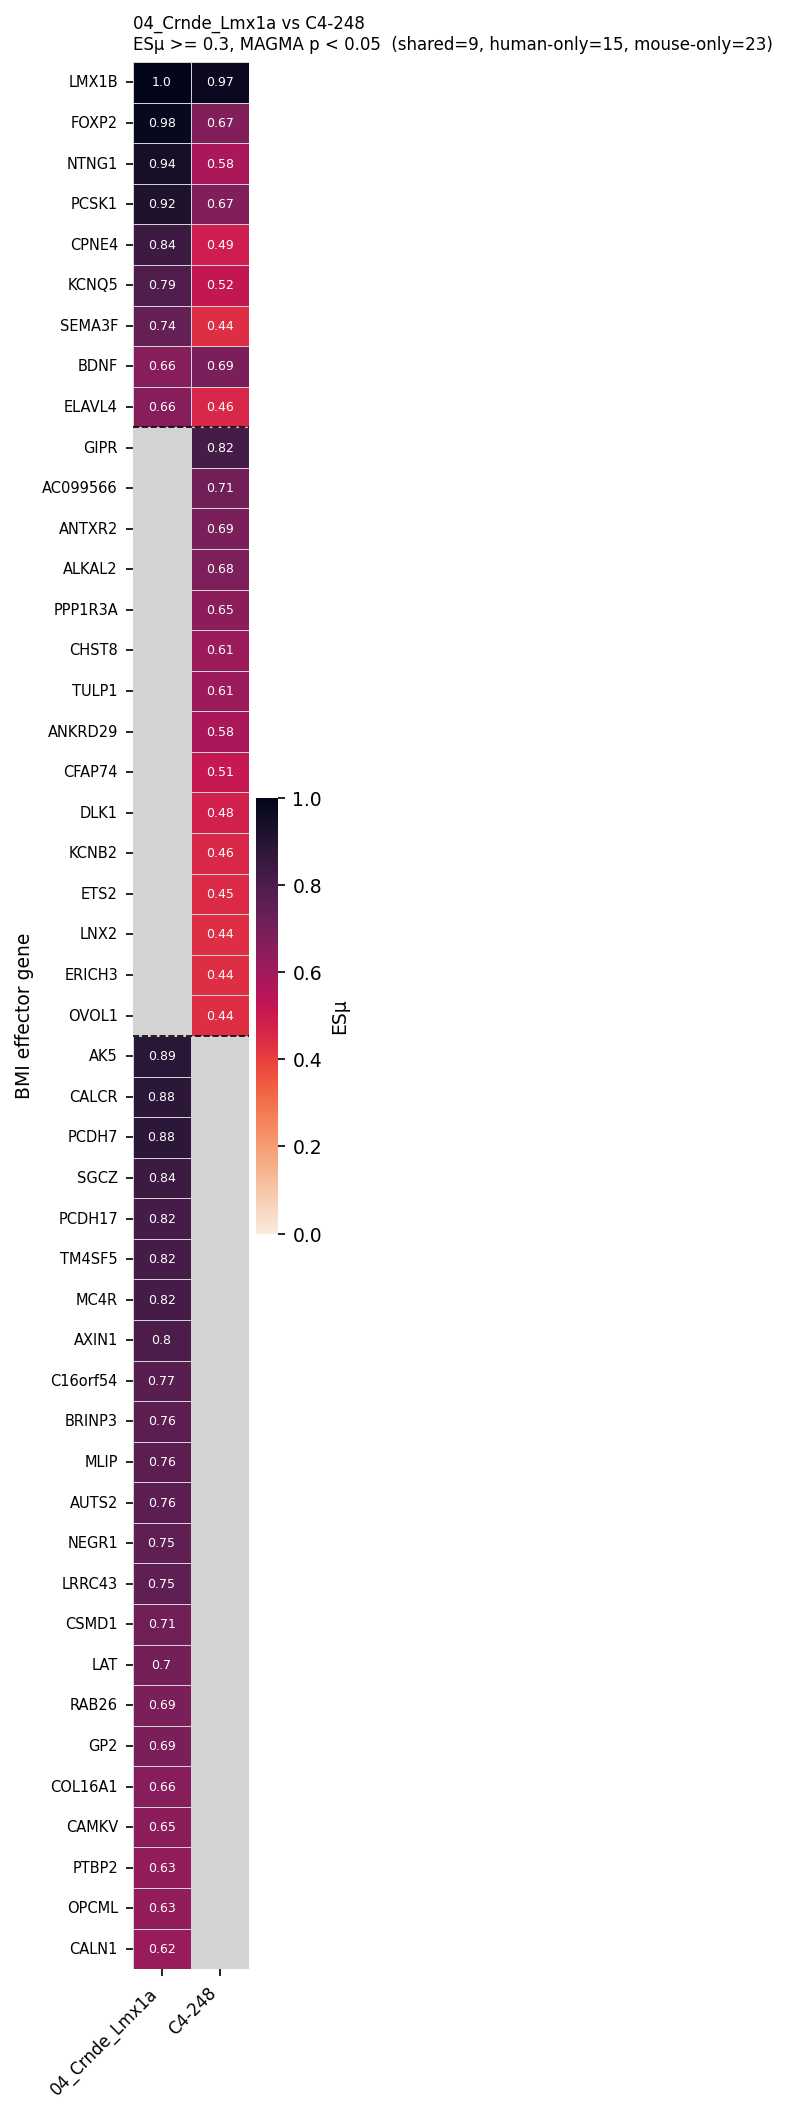

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

MOUSE_PATH   = "detailed_celltype_annotation__BMI_Yengo2018.effector_genes.txt"
C4_PATH      = "named_c4__BMI_Yengo2018.effector_genes.txt"
ESM_MIN      = 0.3
MAGMA_P      = 0.05
MOUSE_TARGET = '04_Crnde_Lmx1a'
C4_TARGET    = 'C4-248'

plt.rcParams.update({'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
                     'figure.dpi': 150, 'savefig.dpi': 300,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})
cmap = sns.color_palette("rocket_r", as_cmap=True)
cmap.set_bad(color='lightgray')

# Load and filter
eff_c4 = pd.read_csv(C4_PATH, sep='\t')
eff_c4['cluster_id'] = eff_c4['annotation'].str.extract(r'^C4_(\d+)').apply(
    lambda x: 'C4-' + x[0] if pd.notna(x[0]) else np.nan, axis=1)
human_filt = eff_c4[(eff_c4['cluster_id'] == C4_TARGET) &
                    (eff_c4['esmu'] >= ESM_MIN) &
                    (eff_c4['magma_gene_pval'] < MAGMA_P)].copy()

eff_mouse = pd.read_csv(MOUSE_PATH, sep='\t')
mouse_filt = eff_mouse[(eff_mouse['annotation'] == MOUSE_TARGET) &
                       (eff_mouse['esmu'] >= ESM_MIN) &
                       (eff_mouse['magma_gene_pval'] < MAGMA_P)].copy()

human_esmu = human_filt.set_index('gene_symbol')['esmu']
mouse_esmu = mouse_filt.set_index('gene_symbol')['esmu']
human_genes = set(human_esmu.index)
mouse_genes = set(mouse_esmu.index)
shared      = human_genes & mouse_genes

print(f"Human: {len(human_genes)}  Mouse: {len(mouse_genes)}  Shared: {len(shared)}")

# Union ordering: shared first (by max ESmu), then human-only, then mouse-only
shared_sorted     = sorted(shared,              key=lambda g: -max(human_esmu[g], mouse_esmu[g]))
human_only_sorted = sorted(human_genes - shared, key=lambda g: -human_esmu[g])
mouse_only_sorted = sorted(mouse_genes - shared, key=lambda g: -mouse_esmu[g])
gene_order = shared_sorted + human_only_sorted + mouse_only_sorted

mat = pd.DataFrame(index=[MOUSE_TARGET, C4_TARGET], columns=gene_order, dtype=float)
mat.loc[MOUSE_TARGET] = mouse_esmu.reindex(gene_order)
mat.loc[C4_TARGET]    = human_esmu.reindex(gene_order)
mat = mat.T

fig_h = max(3, len(gene_order) * 0.28 + 1.0)
fig, ax = plt.subplots(figsize=(2.5, fig_h))

sns.heatmap(mat, ax=ax,
            cmap=cmap, vmin=0, vmax=1.0,
            linewidths=0.35, linecolor='lightgrey',
            mask=mat.isna(),
            xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'ESµ', 'shrink': 0.6},
            annot=mat.round(2), fmt='', annot_kws={'fontsize': 6})

ax.set_xticklabels(ax.get_xticklabels(), fontsize=8, rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7, rotation=0)
ax.set_ylabel('BMI effector gene', fontsize=9)
ax.set_xlabel('')

# Section dividers for shared / human-only / mouse-only
for boundary in [len(shared_sorted), len(shared_sorted) + len(human_only_sorted)]:
    if 0 < boundary < len(gene_order):
        ax.axhline(boundary, color='black', lw=0.8, ls='--')

ax.set_title(f'{MOUSE_TARGET} vs {C4_TARGET}\n'
             f'ESµ >= {ESM_MIN}, MAGMA p < {MAGMA_P}  '
             f'(shared={len(shared_sorted)}, '
             f'human-only={len(human_only_sorted)}, '
             f'mouse-only={len(mouse_only_sorted)})',
             fontsize=8, loc='left')

plt.tight_layout()
plt.savefig('Supplementary_Figure_5.pdf', bbox_inches='tight')
plt.show()

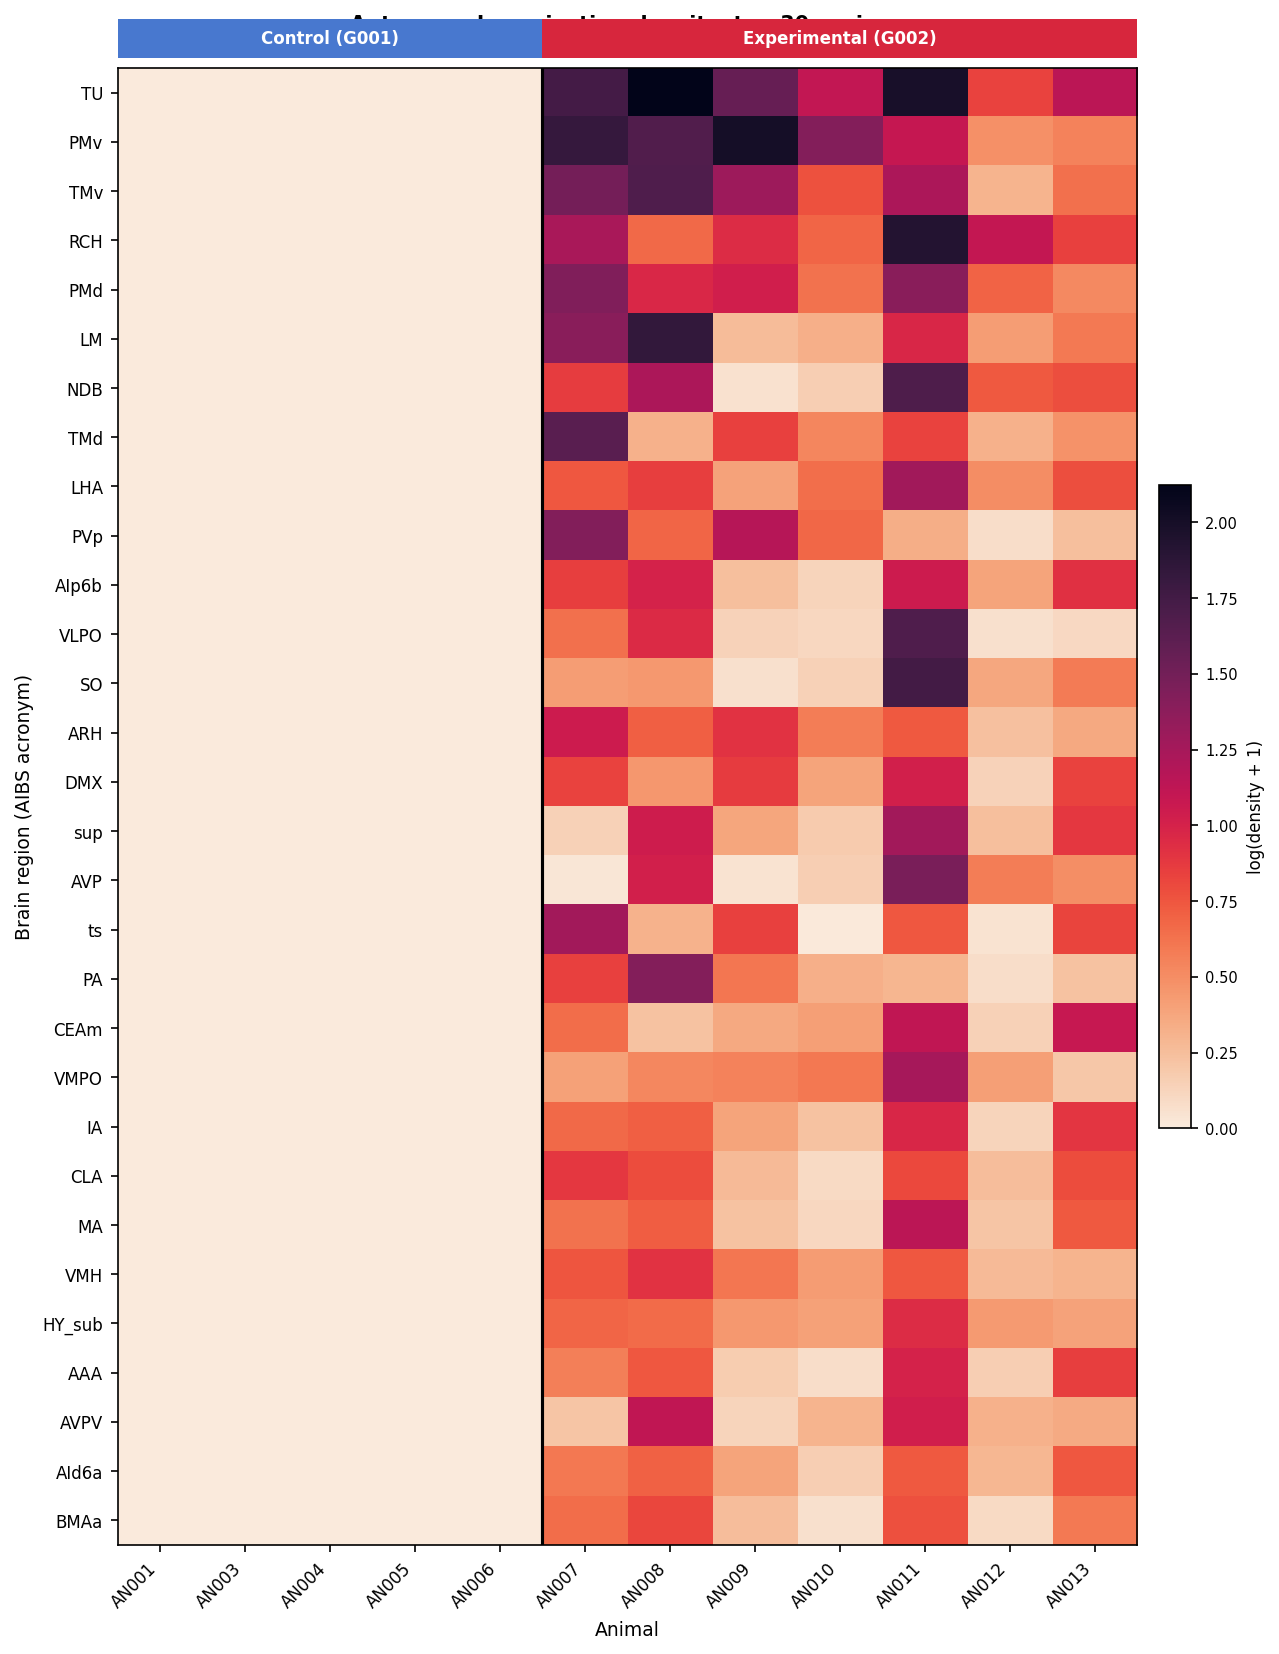

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LogNorm
import seaborn as sns

mpl.rcParams.update({'font.size': 9, 'pdf.fonttype': 42, 'ps.fonttype': 42})
cmap = sns.color_palette("rocket_r", as_cmap=True)
# ── Load and merge ────────────────────────────────────────────────────────────
ann  = pd.read_csv('annotation_info.csv')
dens = pd.read_csv('per_sample_region_density.csv')

df = dens.merge(ann[['aibs_id', 'acronym', 'name']], on='aibs_id', how='left')
df['animal'] = df['sample'].str.extract(r'_(AN\d+)_')

# ── Select top 30 regions by mean density ────────────────────────────────────
TOP_N = 30
top_regions = (df.groupby('acronym')['density_points_per_voxel']
                 .mean()
                 .sort_values(ascending=False)
                 .head(TOP_N)
                 .index.tolist())

df_top = df[df['acronym'].isin(top_regions)].copy()

# ── Pivot: rows = regions, cols = animals ─────────────────────────────────────
mat = df_top.pivot_table(index='acronym',
                          columns='animal',
                          values='density_points_per_voxel',
                          aggfunc='mean')

# Sort rows by mean density descending
mat = mat.loc[mat.mean(axis=1).sort_values(ascending=False).index]

# Sort cols: G001 animals first, then G002
g1 = sorted(df[df['group'] == 'G001']['animal'].unique())
g2 = sorted(df[df['group'] == 'G002']['animal'].unique())
col_order = g1 + g2
mat = mat[col_order]

# log1p transform for display (preserves zeros, compresses high values)
mat_log = np.log1p(mat)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(len(col_order) * 0.55 + 2, TOP_N * 0.32 + 1.5))

im = ax.imshow(mat_log.values, aspect='auto',
               cmap=cmap, interpolation='nearest')

# Axes labels
ax.set_xticks(range(len(col_order)))
ax.set_xticklabels(col_order, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(TOP_N))
ax.set_yticklabels(mat.index, fontsize=8)

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('log(density + 1)', fontsize=8)
cbar.ax.tick_params(labelsize=7)

# Group annotation bar above the heatmap
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks([])

n_g1, n_g2 = len(g1), len(g2)
group_colors = {'G001': '#4878CF', 'G002': '#D7263D'}
for spine in ax.spines.values():
    spine.set_visible(False)

# Draw colored rectangles above each animal group
for j, animal in enumerate(col_order):
    grp = 'G001' if animal in g1 else 'G002'
    ax.add_patch(mpl.patches.Rectangle(
        (j - 0.5, -1.5), 1, 0.8,
        facecolor=group_colors[grp], clip_on=False,
        transform=ax.transData, zorder=4))

# Group labels
ax.text((n_g1 - 1) / 2, -1.1, 'Control (G001)',
        ha='center', va='center', fontsize=8,
        color='white', fontweight='bold',
        transform=ax.transData, zorder=5)
ax.text(n_g1 + (n_g2 - 1) / 2, -1.1, 'Experimental (G002)',
        ha='center', va='center', fontsize=8,
        color='white', fontweight='bold',
        transform=ax.transData, zorder=5)

# Divider between groups
ax.axvline(n_g1 - 0.5, color='black', lw=1.5, zorder=3)

ax.set_title(f'Anterograde projection density, top {TOP_N} regions',
             fontsize=10, fontweight='bold', pad=18)
ax.set_xlabel('Animal', fontsize=9)
ax.set_ylabel('Brain region (AIBS acronym)', fontsize=9)

plt.tight_layout()
plt.savefig('Supplementary_Figure_6.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [3]:
allgenes_bipca_annotated = sc.read("allgenes_bipca_annotated.h5ad")
# ── 1. Atlas-level summary (allgenes_bipca_annotated = snRNA-seq) ─────────────
total_cells   = len(allgenes_bipca_annotated)
n_neurons     = int((allgenes_bipca_annotated.obs['manual_celltype_annotation']
                     .str.lower().str.contains('neuron|neuronal')).sum())
n_glia        = total_cells - n_neurons

ct_counts = (allgenes_bipca_annotated.obs['detailed_celltype_annotation']
             .value_counts().reset_index())
ct_counts.columns = ['celltype', 'n_cells']
ct_counts['dataset'] = 'snRNA-seq_atlas'

In [4]:
# sex breakdown per celltype
sex_ct = (allgenes_bipca_annotated.obs
          .groupby(['detailed_celltype_annotation', 'sex'])
          .size().unstack(fill_value=0).reset_index())
sex_ct.columns.name = None
sex_ct = sex_ct.rename(columns={'detailed_celltype_annotation': 'celltype'})

# area breakdown per celltype
area_ct = (allgenes_bipca_annotated.obs
           .groupby(['detailed_celltype_annotation', 'area'])
           .size().unstack(fill_value=0).reset_index())
area_ct.columns.name = None
area_ct = area_ct.rename(columns={'detailed_celltype_annotation': 'celltype'})

ct_summary = (ct_counts
              .merge(sex_ct, on='celltype', how='left')
              .merge(area_ct, on='celltype', how='left', suffixes=('_sex', '_area')))

/scratch/tmp.9729892.bcoester/ipykernel_34920/2089506539.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'sex'])
/scratch/tmp.9729892.bcoester/ipykernel_34920/2089506539.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'area'])


In [5]:
# ── 2. Lmx1a subset (from allgenes_bipca_annotated) ──────────────────────────
lmx1a_types = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp']
lmx1a_mask  = allgenes_bipca_annotated.obs['detailed_celltype_annotation'].isin(lmx1a_types)
lmx1a_obs   = allgenes_bipca_annotated.obs[lmx1a_mask]

lmx1a_ct = (lmx1a_obs['detailed_celltype_annotation']
             .value_counts().reset_index())
lmx1a_ct.columns = ['celltype', 'n_cells']
lmx1a_ct['dataset'] = 'snRNA-seq_Lmx1a_subset'

lmx1a_sex = (lmx1a_obs.groupby(['detailed_celltype_annotation', 'sex'])
              .size().unstack(fill_value=0).reset_index()
              .rename(columns={'detailed_celltype_annotation': 'celltype'}))
lmx1a_sex.columns.name = None

lmx1a_summary = lmx1a_ct.merge(lmx1a_sex, on='celltype', how='left')

/scratch/tmp.9729892.bcoester/ipykernel_34920/1087672475.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lmx1a_sex = (lmx1a_obs.groupby(['detailed_celltype_annotation', 'sex'])


In [6]:
#del adata_mouse
atlas_merged_NTS_LPBN_retro_scran = sc.read("atlas_merged_NTS_LPBN_retro_scran.h5ad")
# Exclude LPBN retrograde dataset before scoring
atlas_merged_NTS_LPBN_retro_scran = atlas_merged_NTS_LPBN_retro_scran[atlas_merged_NTS_LPBN_retro_scran.obs["dataset"] != "LPBN retrograde (v36)"].copy()
atlas_merged_NTS_LPBN_retro_scran

AnnData object with n_obs × n_vars = 205700 × 22180
    obs: 'nCount_RNA', 'nFeature_RNA', 'seurat_clusters', 'size_factors', 'sex', 'area', 'AAV', 'AAV_ratio', 'detailed_celltype_annotation', 'score_detailed_celltype_annotation', 'animal_id', 'lane_id', 'lane', 'sort', 'score_region_collapsed', 'neurotransmitter', 'predicted_spatial_region', 'predicted_spatial_region_norm', 'predicted_spatial_region_filtered', 'predicted_spatial_region_filtered_norm', 'cellect_bmi_detailed', 'cellect_bmi_detailed_BH', 'cellect_bmi_log10', 'detailed_significant_BH', 'manual_celltype_annotation', 'predicted_brain_region', 'predicted_cell_type', 'region_collapsed', 'region_collapsed_filtered', 'cellect_bmi_manual', 'cellect_bmi_manual_BH', 'manual_significant_BH', 'leiden', 'dataset', 'source'
    obsm: 'X_tsne'
    layers: 'scran_normalization'

In [7]:
# ── 3. Merged atlas (atlas_merged_NTS_LPBN_retro_scran) ──────────────────────
merged_ct = (atlas_merged_NTS_LPBN_retro_scran.obs['detailed_celltype_annotation']
             .value_counts().reset_index())
merged_ct.columns = ['celltype', 'n_cells']
merged_ct['dataset'] = 'snRNA-seq_merged'

merged_sex = (atlas_merged_NTS_LPBN_retro_scran.obs
              .groupby(['detailed_celltype_annotation', 'sex'])
              .size().unstack(fill_value=0).reset_index()
              .rename(columns={'detailed_celltype_annotation': 'celltype'}))
merged_sex.columns.name = None

merged_area = (atlas_merged_NTS_LPBN_retro_scran.obs
               .groupby(['detailed_celltype_annotation', 'area'])
               .size().unstack(fill_value=0).reset_index()
               .rename(columns={'detailed_celltype_annotation': 'celltype'}))
merged_area.columns.name = None

merged_summary = (merged_ct
                  .merge(merged_sex, on='celltype', how='left')
                  .merge(merged_area, on='celltype', how='left', suffixes=('_sex', '_area')))

/scratch/tmp.9729892.bcoester/ipykernel_34920/3292270930.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'sex'])
/scratch/tmp.9729892.bcoester/ipykernel_34920/3292270930.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'area'])


In [8]:
# ── 4. Top-level summary table (manuscript text values) ──────────────────────
atlas_summary = pd.DataFrame({
    'metric': [
        'snRNA-seq total nuclei',
        'snRNA-seq neurons',
        'snRNA-seq glia',
        'snRNA-seq neuronal cell types',
        'snRNA-seq glial cell types',
        'snRNA-seq merged total nuclei',
        'snRNA-seq Lmx1a subset total cells',
        'snRNA-seq Lmx1a subset cell types',
        'spatial total cells',
        'spatial sections',
    ],
    'value': [
        total_cells,
        n_neurons,
        n_glia,
        int(allgenes_bipca_annotated.obs['detailed_celltype_annotation']
            .nunique()),
        'see celltype table',
        len(atlas_merged_NTS_LPBN_retro_scran),
        int(lmx1a_mask.sum()),
        len(lmx1a_types),
        289888,  # spatial cells from manuscript/Seurat object
        24,
    ]
})

# ── 5. Write to CSV ───────────────────────────────────────────────────────────
with pd.ExcelWriter('dataset_summary_stats.xlsx', engine='openpyxl') as writer:
    atlas_summary.to_excel(writer, sheet_name='Overview', index=False)
    ct_summary.to_excel(writer, sheet_name='snRNA_celltype_counts', index=False)
    lmx1a_summary.to_excel(writer, sheet_name='Lmx1a_subset_counts', index=False)
    merged_summary.to_excel(writer, sheet_name='Merged_atlas_counts', index=False)

# Also export flat CSVs
atlas_summary.to_csv('summary_overview.csv', index=False)
ct_summary.to_csv('summary_snRNA_celltypes.csv', index=False)
lmx1a_summary.to_csv('summary_Lmx1a_subset.csv', index=False)
merged_summary.to_csv('summary_merged_atlas.csv', index=False)

print(f"snRNA-seq total:   {total_cells:,}")
print(f"Lmx1a subset:      {lmx1a_mask.sum():,}")
print(f"Merged atlas:      {len(atlas_merged_NTS_LPBN_retro_scran):,}")
print("CSV files written.")

snRNA-seq total:   193,989
Lmx1a subset:      11,585
Merged atlas:      205,700
CSV files written.


In [10]:
adata = allgenes_bipca_annotated

# ── 1. Per-sample (animal x lane) metadata table -- matches Suppl. Table 1/2 format ──
per_sample = (
    adata.obs
    .groupby(['hash.mcl.ID', 'orig.ident', 'lane', 'area', 'sex', 'sort'], observed=True)
    .agg(
        n_cells            = ('nCount_RNA', 'size'),
        median_UMI         = ('nCount_RNA', 'median'),
        median_genes       = ('nFeature_RNA', 'median'),
        mean_UMI           = ('nCount_RNA', 'mean'),
        mean_genes         = ('nFeature_RNA', 'mean'),
        pct_AAV_positive   = ('AAV', lambda x: round(100 * x.sum() / len(x), 2)),
    )
    .reset_index()
    .rename(columns={
        'hash.mcl.ID': 'animal_id',
        'orig.ident':  'sample_id',
        'lane':        'sequencing_lane',
        'area':        'injection_target',
        'sex':         'sex',
        'sort':        'sort_probability_mean',
    })
)
# Replace the four .astype(int) lines with NaN-safe versions
per_sample['median_UMI']   = per_sample['median_UMI'].round(0).astype('Int64')
per_sample['median_genes'] = per_sample['median_genes'].round(0).astype('Int64')
per_sample['mean_UMI']     = per_sample['mean_UMI'].round(0).astype('Int64')
per_sample['mean_genes']   = per_sample['mean_genes'].round(0).astype('Int64')

# ── 2. Per-celltype summary table -- matches Suppl. Table 3 format ────────────
per_celltype = (
    adata.obs
    .groupby('detailed_celltype_annotation')
    .agg(
        n_cells      = ('nCount_RNA', 'size'),
        median_UMI   = ('nCount_RNA', 'median'),
        median_genes = ('nFeature_RNA', 'median'),
        n_male       = ('sex', lambda x: (x == 'male').sum()),
        n_female     = ('sex', lambda x: (x == 'female').sum()),
        pct_AAV_pos  = ('AAV', lambda x: round(100 * x.sum() / len(x), 2)),
        neurotransmitter = ('neurotransmitter', lambda x: x.mode()[0] if len(x) > 0 else 'unknown'),
    )
    .reset_index()
    .rename(columns={'detailed_celltype_annotation': 'celltype'})
)
per_celltype['pct_of_total'] = round(100 * per_celltype['n_cells'] / per_celltype['n_cells'].sum(), 2)
per_celltype['median_UMI']   = per_celltype['median_UMI'].round(0).astype('Int64')
per_celltype['median_genes'] = per_celltype['median_genes'].round(0).astype('Int64')
per_celltype = per_celltype.sort_values('n_cells', ascending=False)

# ── 3. Per-area breakdown across celltypes ────────────────────────────────────
area_ct = (
    adata.obs
    .groupby(['detailed_celltype_annotation', 'area'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .rename(columns={'detailed_celltype_annotation': 'celltype'})
)

per_celltype_full = per_celltype.merge(area_ct, on='celltype', how='left')

# ── 4. Lmx1a subset per-sample table ─────────────────────────────────────────
lmx1a_types = ['04_Crnde_Lmx1a', '27_Lmx1a_Ttc6', '32_Gucy2c_Ttc6', '36_Ebf2_Crhbp']
lmx1a_obs   = adata.obs[adata.obs['detailed_celltype_annotation'].isin(lmx1a_types)]

lmx1a_per_sample = (
    lmx1a_obs
    .groupby(['hash.mcl.ID', 'orig.ident', 'lane', 'area', 'sex'])
    .agg(
        n_cells      = ('nCount_RNA', 'size'),
        median_UMI   = ('nCount_RNA', 'median'),
        median_genes = ('nFeature_RNA', 'median'),
    )
    .reset_index()
    .rename(columns={
        'hash.mcl.ID': 'animal_id',
        'orig.ident':  'sample_id',
        'lane':        'sequencing_lane',
        'area':        'injection_target',
    })
)

lmx1a_per_celltype = (
    lmx1a_obs
    .groupby('detailed_celltype_annotation')
    .agg(
        n_cells      = ('nCount_RNA', 'size'),
        median_UMI   = ('nCount_RNA', 'median'),
        median_genes = ('nFeature_RNA', 'median'),
        n_male       = ('sex', lambda x: (x == 'male').sum()),
        n_female     = ('sex', lambda x: (x == 'female').sum()),
    )
    .reset_index()
    .rename(columns={'detailed_celltype_annotation': 'celltype'})
)

# ── 5. Atlas-level overview ───────────────────────────────────────────────────
overview = pd.DataFrame({
    'dataset': [
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq (allgenes_bipca_annotated)',
        'snRNA-seq Lmx1a subset',
        'snRNA-seq Lmx1a subset',
        'snRNA-seq merged (atlas_merged_NTS_LPBN_retro_scran)',
        'Spatial transcriptomics',
        'Spatial transcriptomics',
    ],
    'metric': [
        'Total nuclei',
        'Total neuronal cell types',
        'Total glial cell types',
        'Median UMI per cell',
        'Median genes per cell',
        'N animals',
        'N sequencing lanes',
        'N male',
        'N female',
        'Total cells (4 Lmx1a clusters)',
        'N cell types',
        'Total nuclei',
        'Total segmented cells',
        'N sections',
    ],
    'value': [
        len(adata),
        adata.obs['detailed_celltype_annotation'].nunique(),
        'see celltype table',
        int(adata.obs['nCount_RNA'].median()),
        int(adata.obs['nFeature_RNA'].median()),
        adata.obs['hash.mcl.ID'].nunique(),
        adata.obs['lane'].nunique(),
        int((adata.obs['sex'] == 'male').sum()),
        int((adata.obs['sex'] == 'female').sum()),
        len(lmx1a_obs),
        len(lmx1a_types),
        len(atlas_merged_NTS_LPBN_retro_scran),
        289888,
        24,
    ]
})

# ── 6. Write CSVs ─────────────────────────────────────────────────────────────
overview.to_csv('suppl_table1_overview.csv', index=False)
per_sample.to_csv('suppl_table2_per_sample.csv', index=False)
per_celltype_full.to_csv('suppl_table3_per_celltype.csv', index=False)
lmx1a_per_sample.to_csv('suppl_table4_lmx1a_per_sample.csv', index=False)
lmx1a_per_celltype.to_csv('suppl_table5_lmx1a_per_celltype.csv', index=False)

print(overview.to_string(index=False))
print(f"\nPer-sample rows: {len(per_sample)}")
print(f"Per-celltype rows: {len(per_celltype_full)}")

/scratch/tmp.9729892.bcoester/ipykernel_34920/3445861955.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('detailed_celltype_annotation')
/scratch/tmp.9729892.bcoester/ipykernel_34920/3445861955.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['detailed_celltype_annotation', 'area'])
/scratch/tmp.9729892.bcoester/ipykernel_34920/3445861955.py:70: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .g

                                             dataset                         metric              value
                snRNA-seq (allgenes_bipca_annotated)                   Total nuclei             193989
                snRNA-seq (allgenes_bipca_annotated)      Total neuronal cell types                 62
                snRNA-seq (allgenes_bipca_annotated)         Total glial cell types see celltype table
                snRNA-seq (allgenes_bipca_annotated)            Median UMI per cell               4070
                snRNA-seq (allgenes_bipca_annotated)          Median genes per cell               2272
                snRNA-seq (allgenes_bipca_annotated)                      N animals                 58
                snRNA-seq (allgenes_bipca_annotated)             N sequencing lanes                  2
                snRNA-seq (allgenes_bipca_annotated)                         N male              87944
                snRNA-seq (allgenes_bipca_annotated)                     